In [1]:
import illustris_python as il
import numpy as np
from astropy.table import *
import matplotlib.pyplot as plt
from sklearn.neighbors import KDTree
import matplotlib 
from statsmodels.nonparametric.smoothers_lowess import lowess
import os
import seaborn as sns
from tqdm import tqdm
from datetime import datetime

matplotlib.rcParams['xtick.direction'] = 'in'
matplotlib.rcParams['ytick.direction'] = 'in'
matplotlib.rcParams['xtick.labelsize'] = 13
matplotlib.rcParams['ytick.labelsize'] = 13

### set binning

In [2]:
bin_number = 14
bin_edges = 10 ** np.linspace(1.0, 2.845, num=bin_number + 1)
areas = np.array([])
for i in range(len(bin_edges[:-1])):
    areas = np.append(areas, (bin_edges[i + 1] ** 2 - bin_edges[i] ** 2) * np.pi)

### projected profiles

In [20]:
# half mass radius definition: ['SubhaloMassInRadType'][:,4]
# surface magnitude definition: ['SubhaloStellarPhotometricsMassInRad']

def radial(massive_central_halos,subhalos,z,sat_cut_low,sat_cut_high, ssfq='all', proj_collapse=0):
    proj = np.delete(np.array([0,1,2]),proj_collapse)
    subhalos['SubhaloSFR'][subhalos['SubhaloSFR']==0.0] = 1e-10
    
    # cosmological scale factor
    a=1/(1+z)
    sat_masscut = 10**(sat_cut_low-10) # in 10^10 M_sun
    sat_masscut_high = 10**(sat_cut_high-10) # in 10^10 M_sun

    # satellite galaxy mass cut logM=9.5
    subhalos_masscut = subhalos[subhalos['SubhaloStellarPhotometricsMassInRad']>sat_masscut*0.704]  # x*10^10 M_sun / h
    subhalos_masscut = subhalos_masscut[subhalos_masscut['SubhaloStellarPhotometricsMassInRad']<sat_masscut_high*0.704]
    
    # make KD Trees for searching/slicing
    tree = KDTree(subhalos_masscut['SubhaloPos'])
    tree_2d = KDTree(subhalos_masscut['SubhaloPos'][:,proj])

    radial_tot = np.zeros(bin_number)
    massive_count = 0
    for i in tqdm(range(len(massive_central_halos))):
        # find the subhalo that host central galaxy
        halo = massive_central_halos[i]
        first_subhalo = subhalos[halo['GroupFirstSub']]
    
        # cylinder shape selection
        ind = tree_2d.query_radius([halo['GroupPos'][proj]],bin_edges[-1]/a*0.704,count_only=False) # comoving kpc / h
        cat_neighbors = subhalos_masscut[ind[0]]
        cat_neighbors = cat_neighbors[abs(cat_neighbors['SubhaloPos'][:,proj_collapse]-halo['GroupPos'][proj_collapse])<bin_edges[-1]*1*0.704]
    
        # isolation criteria
        cat_massive_neighbors = cat_neighbors[cat_neighbors['SubhaloStellarPhotometricsMassInRad']>first_subhalo['SubhaloStellarPhotometricsMassInRad']]
        if len(cat_massive_neighbors)>=2:
            continue
        elif len(cat_neighbors)==0:
            continue 
    
        # ssfr selection
        log_ssfr_sats = np.log10(cat_neighbors['SubhaloSFR']/1e10/0.704/cat_neighbors['SubhaloStellarPhotometricsMassInRad'])
        if ssfq == 'ssf':
            cat_neighbors = cat_neighbors[log_ssfr_sats>-11]
        elif ssfq == 'sq':
            cat_neighbors = cat_neighbors[log_ssfr_sats<-11]
        else:
            pass
        
        if len(cat_neighbors)==0:
            continue
        
        # radial distribution measurement
        radial = [] 
        subtree = KDTree(cat_neighbors['SubhaloPos'][:,proj])
        for bin_edge in bin_edges:
            ind = subtree.query_radius([halo['GroupPos'][proj]],bin_edge/a*0.704,count_only=True) # comoving kpc / h
            radial.append(ind[0])
        
        radial = np.diff(np.array(radial))
        radial_tot += radial
        massive_count += 1
    
    return radial_tot, np.sqrt(radial_tot), massive_count

def load_subhalo_halo(basePath, snap, cen_cut_low,cen_cut_high=13.0):
    header = il.groupcat.loadHeader(basePath,72)
    boxsize = header['BoxSize']
    central_masscut_low = 10**(cen_cut_low-10) # in 10^10 M_sun
    central_masscut_high = 10**(cen_cut_high-10) # in 10^10 M_sun
    print('start loading... mass cut = '+str(central_masscut_low)+' '+str(central_masscut_high))
    
    # load subhalos
    fields = ['SubhaloPos','SubhaloMass','SubhaloMassInRadType','SubhaloStellarPhotometrics','SubhaloSFR','SubhaloStellarPhotometricsMassInRad']
    subhalos = il.groupcat.loadSubhalos(basePath,snap,fields=fields)
    del subhalos['count']
    subhalos = Table(subhalos)
    print('load subhalos done, total number is ' + str(len(subhalos)))

    # load halos
    halos = il.groupcat.loadHalos(basePath,snap,fields=['GroupFirstSub','GroupPos','GroupMass','Group_R_Crit200'])
    del halos['count']
    halos = Table(halos)
    print('load Halos done, total number is ' + str(len(halos)))
    
    # cut massive central galaxies
    central_ids = halos['GroupFirstSub']
    halos = halos[central_ids<1000000000]
    central_ids = central_ids[central_ids<1000000000]
    first_subhalos = subhalos[central_ids]
    massive_central_halos = halos[np.logical_and(first_subhalos['SubhaloStellarPhotometricsMassInRad']>central_masscut_low*0.704, first_subhalos['SubhaloStellarPhotometricsMassInRad']<central_masscut_high*0.704)]
    print('halos with massive central: ',len(massive_central_halos))
    
    # cut off centrals that are close to edge
    mask = []
    for i in tqdm(range(len(massive_central_halos))):
        halo = massive_central_halos[i]
        central_on_edge = False
        for i in range(3):
            if abs(boxsize/2-subhalos[halo['GroupFirstSub']]['SubhaloPos'][i])>boxsize/2-bin_edges[-1]:
                central_on_edge = True
            
        if central_on_edge == True: 
            mask.append(False)
        else:
            mask.append(True)
    
    massive_central_halos = massive_central_halos[mask]
    return massive_central_halos, subhalos


def smf(massive_central_halos,subhalos,z,sat_cut_low,sat_cut_high, ssfq='all', proj_collapse=0):
    proj = np.delete(np.array([0,1,2]),proj_collapse) # the other two direction ( not lone of sight )
    subhalos['SubhaloSFR'][subhalos['SubhaloSFR']==0.0] = 1e-10
    
    # cosmological scale factor
    a=1/(1+z)
    sat_masscut = 10**(sat_cut_low-10) # in 10^10 M_sun
    sat_masscut_high = 10**(sat_cut_high-10) # in 10^10 M_sun

    # satellite galaxy mass cut logM=8.0
    subhalos_masscut = subhalos[subhalos['SubhaloStellarPhotometricsMassInRad']/0.704>sat_masscut]  # x*10^10 M_sun
    subhalos_masscut = subhalos_masscut[subhalos_masscut['SubhaloStellarPhotometricsMassInRad']/0.704<sat_masscut_high]
    
    # make KD Trees for searching/slicing
    tree = KDTree(subhalos_masscut['SubhaloPos'])
    tree_2d = KDTree(subhalos_masscut['SubhaloPos'][:,proj])
    
    mass_bin_number = 35
    mass_bin_edges = np.linspace(8.0,12.0,mass_bin_number)
    smf_tot = np.zeros(mass_bin_number-1)
    massive_count = 0
    for i in tqdm(range(len(massive_central_halos))):
        # find the subhalo that host central galaxy
        halo = massive_central_halos[i]
        r200 = halo['Group_R_Crit200'] # in comoving kpc / h
        first_subhalo = subhalos[halo['GroupFirstSub']]
        print(round(np.log10(first_subhalo['SubhaloStellarPhotometricsMassInRad']/0.704)+10,2),round(r200*a/0.704,1))
    
        # cylinder shape selection #####
        # circular selection
        ind = tree_2d.query_radius([halo['GroupPos'][proj]],r200, count_only=False) # comoving kpc / h
        cat_neighbors = subhalos_masscut[ind[0]]
        
        # along the line of sight
        cat_neighbors = cat_neighbors[abs(cat_neighbors['SubhaloPos'][:,proj_collapse]-halo['GroupPos'][proj_collapse])<r200]
        cat_neighbors = cat_neighbors[abs(cat_neighbors['SubhaloPos'][:,proj_collapse]-halo['GroupPos'][proj_collapse])>1]
        #######
        
        # isolation criteria
        cat_massive_neighbors = cat_neighbors[cat_neighbors['SubhaloStellarPhotometricsMassInRad']>first_subhalo['SubhaloStellarPhotometricsMassInRad']]
        if len(cat_massive_neighbors)>=2:
            continue
        elif len(cat_neighbors)==0:
            continue 
    
        # ssfr selection
        log_ssfr_sats = np.log10(cat_neighbors['SubhaloSFR']/1e10/0.704/cat_neighbors['SubhaloStellarPhotometricsMassInRad'])
        if ssfq == 'ssf':
            cat_neighbors = cat_neighbors[log_ssfr_sats>-11]
        elif ssfq == 'sq':
            cat_neighbors = cat_neighbors[log_ssfr_sats<-11]
        else:
            pass
        
        if len(cat_neighbors)==0:
            continue
            
        # radial distribution measurement
        mass_neighbors = np.log10(cat_neighbors['SubhaloStellarPhotometricsMassInRad']/0.704)+10
        smf = np.histogram(mass_neighbors, bins=mass_bin_edges)[0]
        smf_tot = smf_tot+smf
        
        massive_count += 1
        
    return smf_tot, np.sqrt(smf_tot), massive_count

In [151]:
# Illustris 
path = 'sims.illustris/Illustris-1/output'
m_il,s_il=load_subhalo_halo(path,108,11.2)  # z=0.4
radial_il_tuple = radial(m_il,s_il,0.4,9.5,13.0)

start loading... mass cut = 15.84893192461111
load subhalos done, total number is 4643142
load Halos done, total number is 6828783



KeyboardInterrupt



In [5]:
# TNG
path = 'sims.TNG/TNG300-1/output/'
m_tng,s_tng=load_subhalo_halo(path,72,11.2)  # z=0.4
radial_tng_tuple = radial(m_tng,s_tng,0.4,9.5,13.0)

start loading... mass cut = 15.84893192461111



KeyboardInterrupt



In [136]:
# masscut for central galaxy
def mcen(z, cut_type='fixed'):
    if cut_type == 'moving':
        return 11.4-0.16*z
    else:
        return 11.3
#     return 11.15
#     return 11.41-0.4*z

# calculate and load in halos and subhalos
z=1.0; snap=50
mass_sat_low = 9.5
mass_sat_high = 12.0

m_tng,s_tng = load_subhalo_halo('sims.TNG/TNG300-1/output/',snap, mcen(z))
# m_il2,s_il2=load_subhalo_halo('sims.TNG/TNG300-1/output/',63, mcen(0.6))
# m_il3,s_il3=load_subhalo_halo('sims.TNG/TNG300-1/output/',57, mcen(0.76))
# m_il4,s_il4=load_subhalo_halo('sims.TNG/TNG300-1/output/',50, mcen(1.00))

start loading... mass cut = 19.95262314968883
load subhalos done, total number is 17120875
load Halos done, total number is 19595267
halos with massive central:  171


100%|██████████| 171/171 [00:00<00:00, 16443.35it/s]


In [152]:
radial_tng_tuple = radial(m_tng,s_tng,z, mass_sat_low, mass_sat_high)
radial_tng_tuple = np.array(radial_tng_tuple,dtype=object)
np.save('radial_tng_'+str(z)+'_'+str(mass_sat_low)+'_'+str(mass_sat_high)+'.npy',radial_tng_tuple)

start loading... mass cut = 15.84893192461111
load subhalos done, total number is 15565344
load Halos done, total number is 18534578
halos with massive central:  613


100%|██████████| 606/606 [00:02<00:00, 271.10it/s]


#### Satellite Mass Function

In [17]:
path = 'sims.TNG/TNG300-1/output/'

snap=75
m_tng_75,s_tng_75=load_subhalo_halo(path,snap,11.2,11.5)  # z=0.35

snap=61
m_tng_61,s_tng_61=load_subhalo_halo(path,snap,11.2,11.5)  # z=0.65

snap=51
m_tng_51,s_tng_51=load_subhalo_halo(path,snap,11.2,11.5)  # z=0.95

snap=43
m_tng_43,s_tng_43=load_subhalo_halo(path,snap,11.2,11.5)  # z=1.3

start loading... mass cut = 15.84893192461111 31.622776601683793
load subhalos done, total number is 15421943
load Halos done, total number is 18426014
halos with massive central:  534


100%|██████████| 534/534 [00:00<00:00, 52929.35it/s]

start loading... mass cut = 15.84893192461111 31.622776601683793


load subhalos done, total number is 16225447
load Halos done, total number is 18984585
halos with massive central:  333


100%|██████████| 333/333 [00:00<00:00, 51639.86it/s]

...

load subhalos done, total number is 17011761
load Halos done, total number is 19516414
halos with massive central:  231


100%|██████████| 231/231 [00:00<00:00, 51318.02it/s]

start loading... mass cut = 15.84893192461111 31.622776601683793


load subhalos done, total number is 17787017
load Halos done, total number is 20053236
halos with massive central:  190


100%|██████████| 190/190 [00:00<00:00, 51533.74it/s]


 10%|▉         | 52/531 [00:00<00:00, 512.49it/s]

11.24 1052.5
11.39 1109.3
11.43 1181.9
11.47 1016.1
11.3 940.2
11.36 915.5
11.44 985.3
11.48 960.1
11.39 1060.1
11.32 1066.4
11.46 1013.9
11.43 1075.0
11.44 1085.5
11.37 1045.9
11.3 1013.0
11.29 931.1
11.32 986.0
11.3 945.0
11.48 1031.6
11.44 996.4
11.43 803.6
11.33 903.4
11.45 961.8
11.5 942.6
11.45 915.4
11.3 889.7
11.45 901.3
11.31 955.0
11.35 935.9
11.22 953.1
11.31 852.5
11.22 923.1
11.49 922.6
11.32 743.9
11.34 960.5
11.47 936.9
11.49 880.3
11.37 925.3
11.36 639.6
11.26 816.4
11.36 775.7
11.42 749.6
11.31 913.4
11.26 861.7
11.47 786.8
11.41 830.4
11.43 882.9
11.33 853.0
11.46 922.6
11.49 782.9
11.4 879.3
11.46 874.1
11.29 858.0
11.35 867.0
11.37 826.4
11.45 744.1
11.49 859.8
11.32 877.8
11.42 735.7
11.41 664.7
11.3 898.8
11.47 883.1
11.45 829.8
11.4 794.1
11.32 882.9
11.48 672.8
11.26 885.9
11.38 840.2
11.28 641.2
11.21 869.0
11.41 732.6
11.34 833.9
11.32 825.6
11.4 833.5
11.49 688.2
11.48 877.3
11.29 833.6
11.3 832.7
11.4 826.2
11.37 833.1
11.25 871.7
11.47 828.4
11.38 700.0
11.

 30%|███       | 161/531 [00:00<00:00, 518.97it/s]

11.49 795.2
11.35 754.6
11.45 788.0
11.42 750.8
11.32 800.9
11.43 799.8
11.44 787.4
11.42 784.7
11.25 680.4
11.36 744.7
11.42 802.8
11.48 749.0
11.42 811.2
11.46 807.1
11.22 751.1
11.28 786.6
11.23 793.4
11.39 768.7
11.42 714.2
11.2 612.7
11.24 769.5
11.32 800.3
11.28 667.9
11.27 766.9
11.21 621.9
11.22 738.1
11.47 781.9
11.47 742.4
11.32 778.3
11.2 744.0
11.43 775.5
11.4 777.6
11.34 762.8
11.39 707.7
11.43 766.7
11.25 746.4
11.34 640.6
11.42 776.6
11.24 624.0
11.23 756.8
11.34 774.2
11.37 767.5
11.22 784.2
11.29 784.3
11.23 770.6
11.27 740.5
11.42 758.5
11.2 572.9
11.21 705.6
11.29 720.6
11.33 653.1
11.36 768.4
11.33 738.8
11.32 725.7
11.36 726.6
11.24 751.4
11.29 680.0
11.42 692.9
11.31 655.8
11.28 636.2
11.48 736.2
11.34 763.8
11.34 724.0
11.44 742.4
11.44 761.6
11.38 631.6
11.38 733.9
11.22 725.1
11.43 727.9
11.36 743.1
11.38 747.8
11.28 738.4
11.31 600.3
11.34 752.4
11.25 734.4
11.33 756.2
11.38 735.0
11.31 709.1
11.23 714.9
11.26 735.6
11.41 750.0
11.36 727.2
11.32 741.6
11.23 75

 50%|█████     | 268/531 [00:00<00:00, 515.00it/s]

...

11.41 341.3
11.25 339.1
11.27 307.3
11.26 347.8
11.24 327.7
11.36 332.1
11.23 340.0
11.31 327.4
11.22 273.5


 28%|██▊       | 53/187 [00:00<00:00, 525.07it/s]

11.44 825.7
11.37 583.5
11.46 695.1
11.45 657.8
11.36 656.7
11.32 597.2
11.41 604.9
11.4 647.9
11.45 647.9
11.37 566.3
11.45 613.3
11.29 523.3
11.5 540.8
11.46 570.8
11.33 566.4
11.28 488.1
11.32 548.5
11.33 472.7
11.46 550.0
11.29 559.5
11.24 547.4
11.38 520.3
11.26 429.3
11.38 520.0
11.34 540.2
11.27 539.1
11.48 523.5
11.24 536.0
11.32 531.9
11.37 489.4
11.4 487.4
11.47 502.1
11.42 482.9
11.27 496.3
11.29 474.3
11.37 479.4
11.41 494.4
11.45 493.6
11.25 497.3
11.25 470.7
11.44 453.5
11.36 433.5
11.31 491.8
11.47 444.0
11.42 483.5
11.3 494.4
11.29 462.7
11.49 408.4
11.41 476.5
11.21 481.2
11.31 438.1
11.5 470.9
11.49 464.0
11.5 473.7
11.31 451.1
11.23 480.1
11.34 404.1
11.4 465.3
11.24 470.1
11.34 466.6
11.22 473.1
11.3 452.0
11.47 451.9
11.34 446.8
11.23 443.6
11.33 455.4
11.46 419.7
11.33 433.3
11.26 457.3
11.27 441.9
11.26 411.3
11.34 420.5
11.42 437.7
11.24 418.0
11.21 451.4
11.37 434.1
11.35 442.5
11.28 411.3
11.47 408.7
11.29 446.5
11.3 388.5
11.2 437.7
11.48 422.6
11.45 435.5
11

100%|██████████| 187/187 [00:00<00:00, 553.65it/s]


11.27 402.1
11.36 357.4
11.25 401.6
11.24 382.9
11.34 379.3
11.21 390.9
11.3 378.3
11.46 348.2
11.21 380.8
11.34 385.5
11.24 314.6
11.23 373.5
11.39 361.5
11.3 366.5
11.22 377.9
11.3 300.1
11.41 379.8
11.32 377.3
11.24 334.4
11.22 375.9
11.27 302.5
11.22 349.0
11.3 345.4
11.23 338.9
11.22 359.8
11.24 351.0
11.38 358.0
11.33 315.5
11.21 275.8
11.27 335.6
11.35 333.1
11.26 339.7
11.31 352.0
11.25 315.5
11.33 347.5
11.26 316.3
11.31 324.4
11.21 325.9
11.42 327.1
11.27 327.3
11.3 321.3
11.42 308.5
11.35 306.5
11.21 315.4
11.3 320.4
11.29 309.9
11.29 274.9
11.24 319.0
11.25 308.9
11.21 302.6
11.24 314.1
11.28 292.3
11.24 311.0
11.44 298.7
11.29 298.6
11.28 308.5
11.21 298.6
11.33 298.2
11.25 303.3
11.26 301.3
11.36 303.6
11.23 303.1
11.36 289.2
11.39 294.6
11.2 290.3
11.22 268.7
11.25 284.1
11.21 283.5
11.34 282.7
11.24 262.1
11.23 267.7
11.26 269.7
11.31 275.1
11.27 243.5
11.2 264.1
11.22 234.7


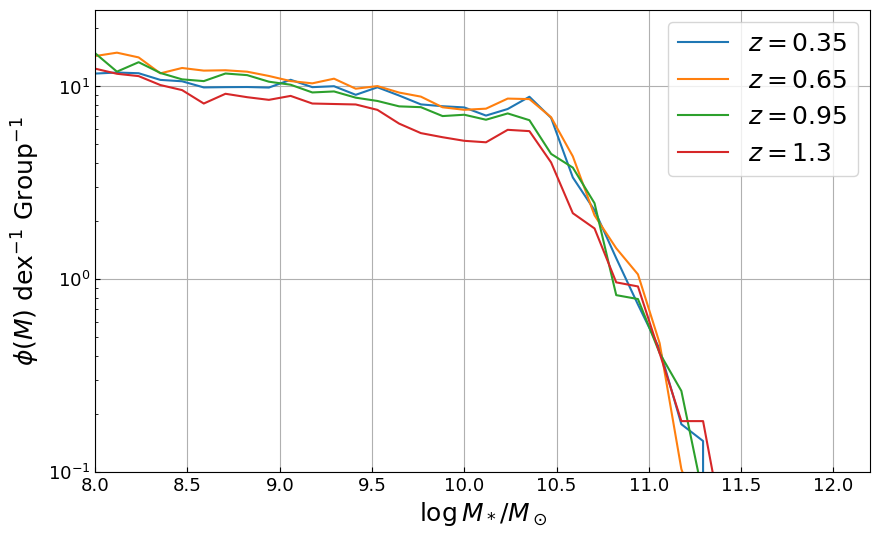

In [21]:
mass_sat_low = 8.0 
mass_sat_high = 12.0
mass_bin_number = 35
mass_bin_edges = np.linspace(mass_sat_low,mass_sat_high,mass_bin_number)
bin_size = mass_bin_edges[1] - mass_bin_edges[0]

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 6))

z=0.35   
smf_tng_tuple = smf(m_tng_75,s_tng_75, z, mass_sat_low, mass_sat_high)
plt.plot(mass_bin_edges[:-1],smf_tng_tuple[0]/smf_tng_tuple[2]/bin_size,label='$z='+str(z)+'$')

z=0.65
smf_tng_tuple = smf(m_tng_61,s_tng_61, z, mass_sat_low, mass_sat_high)
plt.plot(mass_bin_edges[:-1],smf_tng_tuple[0]/smf_tng_tuple[2]/bin_size,label='$z='+str(z)+'$')

z=0.95
smf_tng_tuple = smf(m_tng_51,s_tng_51, z, mass_sat_low, mass_sat_high)
plt.plot(mass_bin_edges[:-1],smf_tng_tuple[0]/smf_tng_tuple[2]/bin_size,label='$z='+str(z)+'$')

z=1.3
smf_tng_tuple = smf(m_tng_43,s_tng_43, z, mass_sat_low, mass_sat_high)
plt.plot(mass_bin_edges[:-1],smf_tng_tuple[0]/smf_tng_tuple[2]/bin_size,label='$z='+str(z)+'$')

plt.xlim([8,12.2])
plt.ylim([1e-1,25])
plt.yscale('log')
plt.xlabel('$\log M_*/M_\odot$',fontsize=18)
plt.ylabel(r'$\phi(M)~\mathrm{dex}^{-1} ~\mathrm{Group}^{-1}$',fontsize=18)
plt.legend(fontsize=18)
plt.grid()

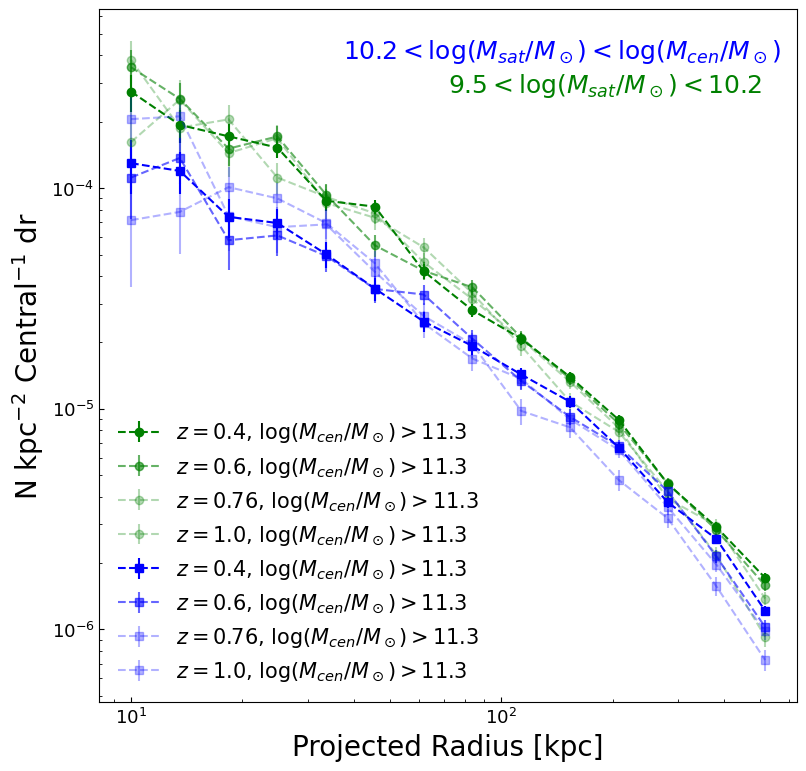

In [10]:
# z-evo plot with fixed masscut on centrals and split mass bins on satellites

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(9, 9))

#### low mass ####

radial_tot_tng1, radial_tot_tng1_err, count_tng1 = np.load('radial_tng_0.4_9.5_10.2.npy',allow_pickle=True)
radial_tot_tng2, radial_tot_tng2_err, count_tng2 = np.load('radial_tng_0.6_9.5_10.2.npy',allow_pickle=True)
radial_tot_tng3, radial_tot_tng3_err, count_tng3 = np.load('radial_tng_0.76_9.5_10.2.npy',allow_pickle=True)
radial_tot_tng4, radial_tot_tng4_err, count_tng4 = np.load('radial_tng_1.0_9.5_10.2.npy',allow_pickle=True)

plt.errorbar(bin_edges[:-1],radial_tot_tng1/areas/count_tng1,yerr=radial_tot_tng1_err/areas/count_tng1,
             fmt='og--',label=r'$z=0.4$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.4),2)),alpha=1)
plt.errorbar(bin_edges[:-1],radial_tot_tng2/areas/count_tng2,yerr=radial_tot_tng2_err/areas/count_tng2,
             fmt='og--',label=r'$z=0.6$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.6),2)),alpha=0.6)
plt.errorbar(bin_edges[:-1],radial_tot_tng3/areas/count_tng3,yerr=radial_tot_tng3_err/areas/count_tng3,
             fmt='og--',label=r'$z=0.76$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.76),2)),alpha=0.3)
plt.errorbar(bin_edges[:-1],radial_tot_tng4/areas/count_tng4,yerr=radial_tot_tng4_err/areas/count_tng4,
             fmt='og--',label=r'$z=1.0$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(1.0),2)),alpha=0.3)

#### high mass ####
# mass_sat_low = 10.2
# mass_sat_high = 12.0

radial_tot_tng1, radial_tot_tng1_err, count_tng1 = np.load('radial_tng_0.4_10.2_12.0.npy',allow_pickle=True)
radial_tot_tng2, radial_tot_tng2_err, count_tng2 = np.load('radial_tng_0.6_10.2_12.0.npy',allow_pickle=True)
radial_tot_tng3, radial_tot_tng3_err, count_tng3 = np.load('radial_tng_0.76_10.2_12.0.npy',allow_pickle=True)
radial_tot_tng4, radial_tot_tng4_err, count_tng4 = np.load('radial_tng_1.0_10.2_12.0.npy',allow_pickle=True)

plt.errorbar(bin_edges[:-1],radial_tot_tng1/areas/count_tng1,yerr=radial_tot_tng1_err/areas/count_tng1,
             fmt='sb--',label=r'$z=0.4$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.4),2)),alpha=1)
plt.errorbar(bin_edges[:-1],radial_tot_tng2/areas/count_tng2,yerr=radial_tot_tng2_err/areas/count_tng2,
             fmt='sb--',label=r'$z=0.6$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.6),2)),alpha=0.6)
plt.errorbar(bin_edges[:-1],radial_tot_tng3/areas/count_tng3,yerr=radial_tot_tng3_err/areas/count_tng3,
             fmt='sb--',label=r'$z=0.76$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(0.76),2)),alpha=0.3)
plt.errorbar(bin_edges[:-1],radial_tot_tng4/areas/count_tng4,yerr=radial_tot_tng4_err/areas/count_tng4,
             fmt='sb--',label=r'$z=1.0$, $\log(M_{cen}/M_\odot)>$'+str(round(mcen(1.0),2)),alpha=0.3)
####
# plt.annotate(r'$z=$0.4',xy=([0.08,0.08]),xycoords='axes fraction',fontsize=18,color='k',alpha=1)
# plt.annotate(r'$z=$0.6',xy=([0.08,0.18]),xycoords='axes fraction',fontsize=18,color='k',alpha=0.6)
# plt.annotate(r'$z=$0.76',xy=([0.08,0.28]),xycoords='axes fraction',fontsize=18,color='k',alpha=0.3)

plt.annotate(r'$9.5<\log(M_{sat}/M_\odot)<10.2$',xy=([0.5,0.88]),xycoords='axes fraction',fontsize=18,color='g')
plt.annotate(r'$10.2<\log(M_{sat}/M_\odot)<\log(M_{cen}/M_\odot)$',xy=([0.35,0.93]),xycoords='axes fraction',fontsize=18,color='b')

plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=15,frameon=False,loc='lower left')
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('z_dependence_TNG'+str(mcen(0.4))+'_'+str(mass_sat_low)+'_'+str(mass_sat_high)+'.png')


start loading... mass cut = 14.125375446227554
load subhalos done, total number is 16526599
load Halos done, total number is 19192204
halos with massive central:  447


100%|██████████| 442/442 [00:01<00:00, 292.34it/s]


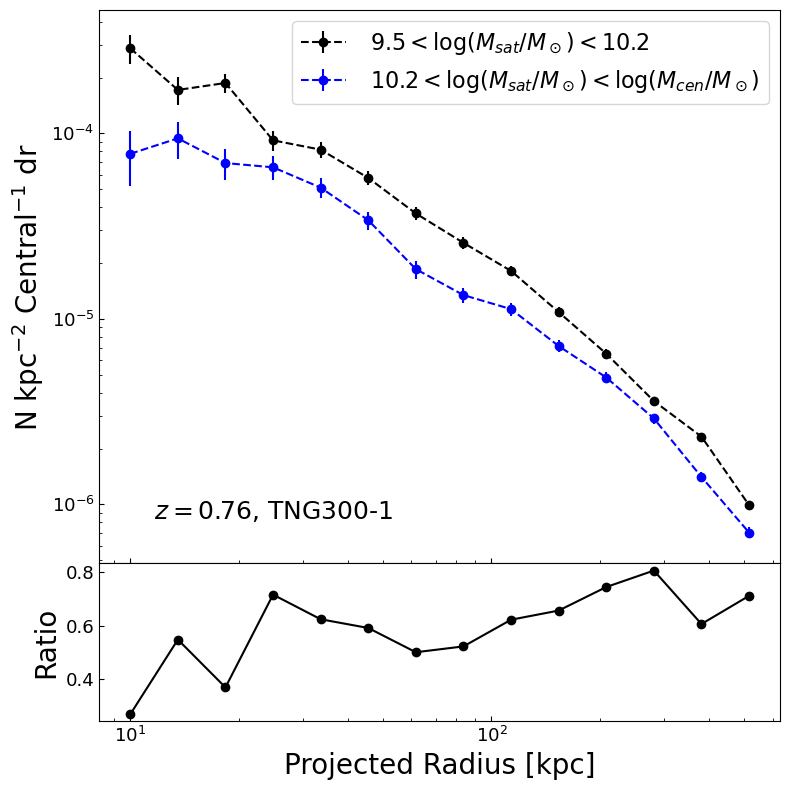

In [24]:
# split low/high sat mass
fig, axs = plt.subplots(2,1, sharex=True,sharey='row', figsize=(8, 8),gridspec_kw={'height_ratios':[3.5,1]})
z=0.76

sim = 'TNG'
basPath = 'sims.'+sim+'/TNG300-1/output/'

# sim = 'illustris'
# basPath = 'sims.'+sim+'/Illustris-1/output'

m_il,s_il=load_subhalo_halo(basPath,57,11.15)
radial_tot_lm,radial_tot_lm_err ,count_lm = radial(m_il,s_il,z,9.5,10.2)
radial_tot_hm,radial_tot_hm_err ,count_hm = radial(m_il,s_il,z,10.2,13.0)

curve_hm = radial_tot_hm/areas/count_hm
curve_lm = radial_tot_lm/areas/count_lm
error_hm = radial_tot_hm_err/areas/count_hm
error_lm = radial_tot_lm_err/areas/count_lm
hm_tuple = (curve_hm,error_hm)
lm_tuple = (curve_lm,error_lm)

np.save('radial_hm_4.npy',np.asarray(hm_tuple))
np.save('radial_lm_4.npy' ,np.asarray(lm_tuple))

axs[0].errorbar(bin_edges[:-1],curve_lm,yerr=radial_tot_lm_err/areas/count_lm,
             fmt='ok--',label=' $9.5<\log(M_{sat}/M_\odot)<10.2$')
axs[0].errorbar(bin_edges[:-1],curve_hm,yerr=radial_tot_hm_err/areas/count_hm,
             fmt='ob--',label=' $10.2<\log(M_{sat}/M_\odot)<\log(M_{cen}/M_\odot)$')

axs[1].errorbar(bin_edges[:-1],curve_hm/curve_lm,yerr=radial_tot_hm_err/areas/count_hm,
             fmt='ok-',label=str(z)+' tng 10.2 - ')

axs[0].annotate(r'$z='+str(z)+'$, TNG300-1',xy=([0.08,0.08]),xycoords='axes fraction',fontsize=18,color='k')
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].legend(fontsize=16,loc='upper right')
axs[1].set_xlabel('Projected Radius [kpc]', fontsize=20)
axs[0].set_ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
axs[1].set_ylabel('Ratio', fontsize=20)
plt.tight_layout()
fig.subplots_adjust(hspace=0)

plt.savefig('split_sat_mass_'+sim+'_'+str(z)+'.png')

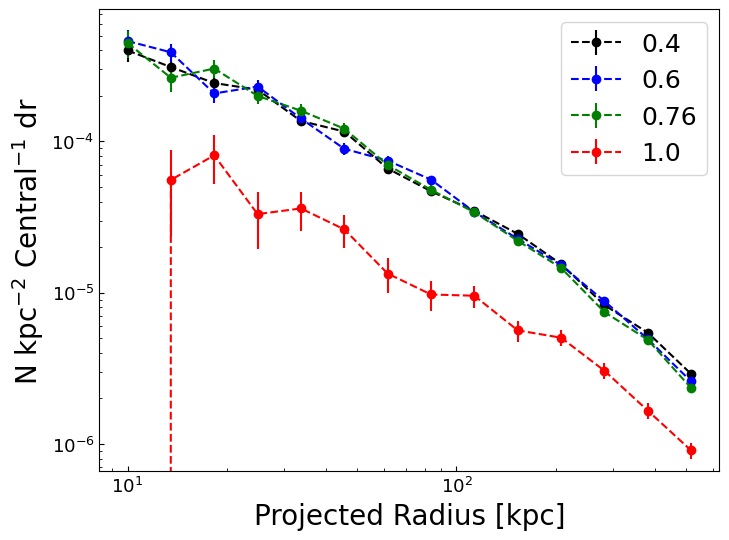

In [25]:
# moving mass cut for centrals
# z-evo plot

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 6))
central_masscut = 11.4-0.16*z
sim = 'TNG'
basPath = 'sims.'+sim+'/TNG300-1/output/'

# sim = 'illustris'
# basPath = 'sims.'+sim+'/Illustris-1/output'

radial_tot_tng,radial_tot_tng_err, count_tng = np.load('radial_tng_0.4_9.5_12.0.npy',allow_pickle=True)
radial_tot_tng2,radial_tot_tng2_err, count_tng2 = np.load('radial_tng_0.6_9.5_12.0.npy',allow_pickle=True)
radial_tot_tng3,radial_tot_tng3_err, count_tng3 = np.load('radial_tng_0.76_9.5_12.0.npy',allow_pickle=True)
radial_tot_tng4,radial_tot_tng4_err, count_tng4 = np.load('radial_tng_1.0_9.5_12.0.npy',allow_pickle=True)

plt.errorbar(bin_edges[:-1],radial_tot_tng/areas/count_tng,yerr=radial_tot_tng_err/areas/count_tng,fmt='ok--',label='0.4')
plt.errorbar(bin_edges[:-1],radial_tot_tng2/areas/count_tng2,yerr=radial_tot_tng2_err/areas/count_tng2,fmt='ob--',label='0.6')
plt.errorbar(bin_edges[:-1],radial_tot_tng3/areas/count_tng3,yerr=radial_tot_tng3_err/areas/count_tng3,fmt='og--',label='0.76')
plt.errorbar(bin_edges[:-1],radial_tot_tng4/areas/count_tng4,yerr=radial_tot_tng4_err/areas/count_tng4,fmt='or--',label='1.0')

plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=18)
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('z_dependence_'+sim+'.png')

start loading... mass cut = 6.309573444801943
load subhalos done, total number is 4372442
load Halos done, total number is 7697109
halos with massive central:  728


100%|██████████| 728/728 [00:00<00:00, 45771.36it/s]

start loading... mass cut = 6.309573444801943


load subhalos done, total number is 14485709
load Halos done, total number is 17625892
halos with massive central:  5408


100%|██████████| 5317/5317 [00:20<00:00, 264.68it/s]


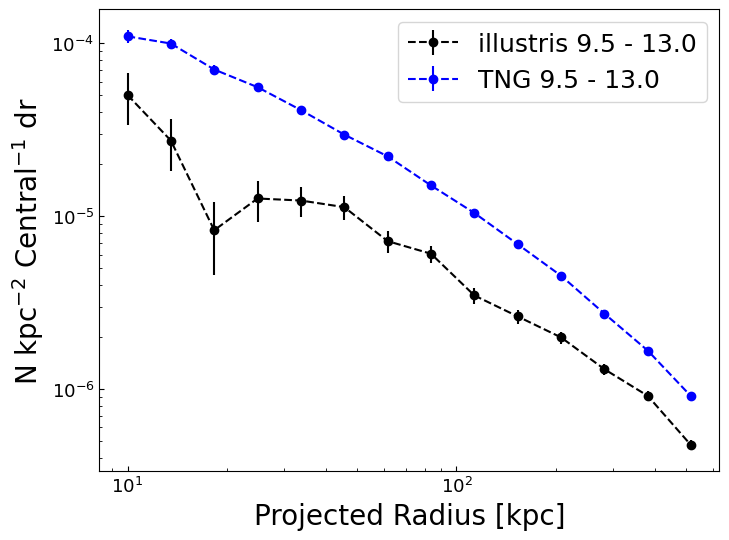

In [26]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 6))

path = 'sims.illustris/Illustris-1/output'
m_il,s_il=load_subhalo_halo(path,134,10.8)  # z=0
path = 'sims.TNG/TNG300-1/output/'
m_tng,s_tng=load_subhalo_halo(path,99,10.8)  # z=0

radial_tot_il,radial_tot_il_err, count_il = radial(m_il,s_il,0,9.5,13.0)
radial_tot_tng,radial_tot_tng_err, count_tng = radial(m_tng,s_tng,0,9.5,13.0)

plt.errorbar(bin_edges[:-1],radial_tot_il/areas/count_il, yerr=radial_tot_il_err/areas/count_il,fmt='ok--',label='illustris 9.5 - 13.0')
plt.errorbar(bin_edges[:-1],radial_tot_tng/areas/count_tng, yerr=radial_tot_tng_err/areas/count_tng,fmt='ob--',label='TNG 9.5 - 13.0')

plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=18)
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('compare_IL_TNG.png')


massive gals: 92 , isolated centrals: 92
massive gals: 756 , isolated centrals: 756


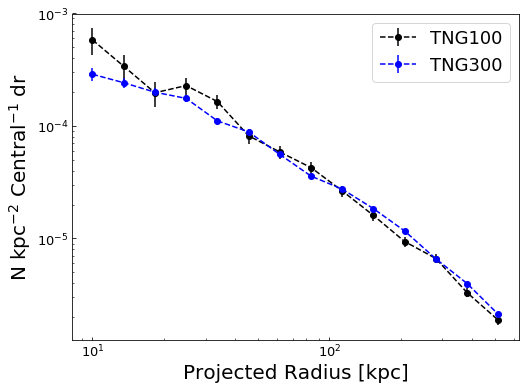

In [22]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 6))

snap = 72; z = 0.4

m_tng,s_tng=load_subhalo_halo('sims.TNG/TNG100-1/output/',snap,11.15)
radial_tot_tng,radial_tot_tng_err, count_tng = radial(m_tng,s_tng,z,9.5,13.0)
m_tng2,s_tng2=load_subhalo_halo('sims.TNG/TNG300-1/output/',snap,11.15)
radial_tot_tng2,radial_tot_tng2_err, count_tng2 = radial(m_tng2,s_tng2,z,9.5,13.0)

plt.errorbar(bin_edges[:-1],radial_tot_tng/areas/count_tng,yerr=radial_tot_tng_err/areas/count_tng,fmt='ok--',label='TNG100')
plt.errorbar(bin_edges[:-1],radial_tot_tng2/areas/count_tng2,yerr=radial_tot_tng2_err/areas/count_tng2,fmt='ob--',label='TNG300')

plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=18)
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('compare_IL_TNG_obs_criteria.png')

### three projections

massive gals: 92 , isolated centrals: 92
massive gals: 92 , isolated centrals: 92
massive gals: 92 , isolated centrals: 92


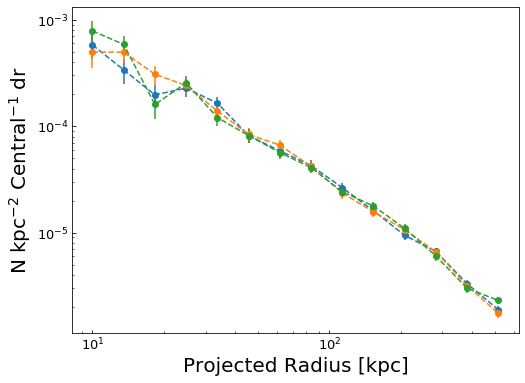

In [12]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 6))

snap = 72; z = 0.4
m_tng,s_tng=load_subhalo_halo('sims.TNG/TNG100-1/output/',snap,11.15)

for proj_collapse in [0,1,2]:
    massive_central_halos, subhalos = load_subhalo_halo('sims.TNG/TNG100-1/output/',snap,11.15)
    radial_tot, radial_tot_err, massive_count = radial(massive_central_halos,subhalos,z, 
                                                             9.5, 13.0, proj_collapse)
    plt.errorbar(bin_edges[:-1],radial_tot/areas/massive_count,
                 yerr=np.sqrt(radial_tot)/areas/massive_count,fmt='o--')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('three_projection_0.4.png')

### split central/Satellite sfq

1. split by $g-r$ color
2. split by sSFR

In [5]:
massive_central_halos,subhalos = load_subhalo_halo('sims.TNG/TNG100-1/output/',72,11.15)
subhalos = subhalos[subhalos['SubhaloStellarPhotometricsMassInRad']>0.316*0.704]
subhalos['SubhaloSFR'][subhalos['SubhaloSFR']==0.0] = 1e-5

g_r      = subhalos['SubhaloStellarPhotometrics'][:,4] - subhalos['SubhaloStellarPhotometrics'][:,5]
mass     = np.log10(subhalos['SubhaloStellarPhotometricsMassInRad']/0.704)+10
log_ssfr = np.log10(subhalos['SubhaloSFR']/(subhalos['SubhaloStellarPhotometricsMassInRad']*1e10/0.704))

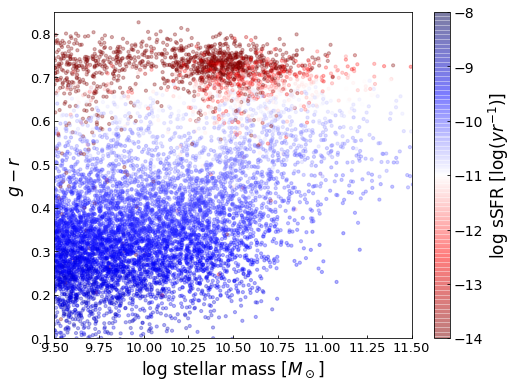

In [6]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 6))
plt.scatter(mass, g_r,s=10,alpha=0.3,c=log_ssfr,vmin=-14, vmax=-8, cmap='seismic_r')

cbar = plt.colorbar() 
cbar.ax.tick_params(labelsize=14) 
cbar.set_label(r'log sSFR [$\log(yr^{-1})$]',size=17)
plt.xlim([9.5,11.5])
plt.ylim([0.1,0.85])
plt.xlabel(r'log stellar mass [$M_\odot$]',fontsize=17)
plt.ylabel(r'$g-r$',fontsize=17)
plt.show() 

### quiescent centrals have more satellites?

Kawin+2014

In [6]:
massive_central_halos,subhalos = load_subhalo_halo('sims.TNG/TNG300-1/output/',72,11.15)
centrals = subhalos[massive_central_halos['GroupFirstSub']]
log_ssfr_central = np.log10(centrals['SubhaloSFR']/(centrals['SubhaloStellarPhotometricsMassInRad']*1e10/0.704))

q_central_halos = massive_central_halos[log_ssfr_central < -11]
sf_central_halos = massive_central_halos[log_ssfr_central > -11]
print(len(q_central_halos),len(sf_central_halos))

430 326


/opt/conda/lib/python3.6/site-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until


massive gals: 430 , isolated centrals: 430
massive gals: 326 , isolated centrals: 326


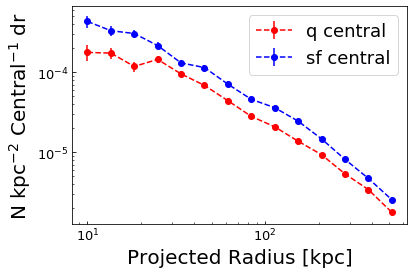

In [8]:
# Obtain `N_BINS` equal frequency bins, in other words percentiles
# N_BINS = 30
# SAMPLE_SIZE=200
# step = 100 / N_BINS

# sf_central_percentiles = [
#     np.percentile(subhalos[sf_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad'], q, axis=0)
#     for q in np.arange(start=step, stop=100, step=step)
# ]

# # Match each observation in the training set to a bin
# q_central_bins = np.digitize(subhalos[q_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad'], sf_central_percentiles)

# # Count the number of values in each training set bin
# q_central_bin_counts = np.bincount(q_central_bins)

# # Weight each observation in the training set based on which bin it is in
# weights = 1 / np.array([q_central_bin_counts[x] for x in q_central_bins])

# # Make the weights sum up to 1
# weights_norm = weights / np.sum(weights)

# np.random.seed(0)
# q_central_halos_matched = np.random.choice(q_central_halos, size=SAMPLE_SIZE, p=weights_norm, replace=False)

sat_masscut=9.5
radial_tot_q,radial_tot_q_err, count_q = radial(q_central_halos,subhalos,0.4,sat_masscut,13.0)
radial_tot_sf,radial_tot_sf_err, count_sf = radial(sf_central_halos,subhalos,0.4,sat_masscut,13.0)

plt.errorbar(bin_edges[:-1],radial_tot_q/areas/count_q,yerr=radial_tot_q_err/areas/count_q,
             fmt='or--',label='q central')
plt.errorbar(bin_edges[:-1],radial_tot_sf/areas/count_sf,yerr=radial_tot_sf_err/areas/count_sf,
             fmt='ob--',label='sf central')

plt.xscale('log')
plt.yscale('log')

plt.legend(fontsize=18)
plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.savefig('sf_q_central.png')

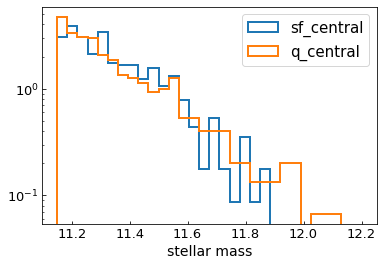

In [10]:
plt.hist(np.log10(subhalos[sf_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad']/0.704)+10,
         range=(11.15,12.2),density=True,histtype='step',linewidth=2,bins=30,label='sf_central')
plt.hist(np.log10(subhalos[q_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad']/0.704)+10,
         range=(11.15,12.2),density=True,histtype='step',linewidth=2,bins=30,label='q_central')

plt.yscale('log')
plt.legend(fontsize=15)
plt.xlabel('stellar mass',fontsize=14)
plt.savefig('central_stellar_mass_hist.png')

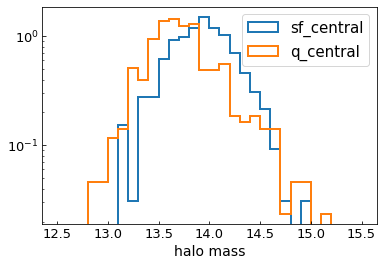

In [11]:
plt.hist(np.log10(sf_central_halos['GroupMass']/0.704)+10,
         range=(12.5,15.5),density=True,histtype='step',linewidth=2,bins=30,label='sf_central')
plt.hist(np.log10(q_central_halos['GroupMass']/0.704)+10,
         range=(12.5,15.5),density=True,histtype='step',linewidth=2,bins=30,label='q_central')

plt.yscale('log')
plt.xlabel('halo mass',fontsize=14)
plt.legend(fontsize=15)
plt.savefig('central_halo_mass_hist.png')

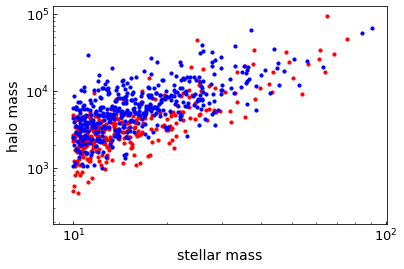

In [8]:
plt.scatter(subhalos[q_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad'],q_central_halos['GroupMass'],color='r',s=10)
plt.scatter(subhalos[sf_central_halos['GroupFirstSub']]['SubhaloStellarPhotometricsMassInRad'],sf_central_halos['GroupMass'],color='b',s=10)

plt.yscale('log')
plt.xscale('log')
plt.xlabel('stellar mass',fontsize=14)
plt.ylabel('halo mass',fontsize=14)
plt.savefig('central_stellar_halo_mass.png')

### Conformity?

massive gals: 272 , isolated centrals: 272
massive gals: 272 , isolated centrals: 269
massive gals: 1187 , isolated centrals: 1186
massive gals: 1187 , isolated centrals: 953


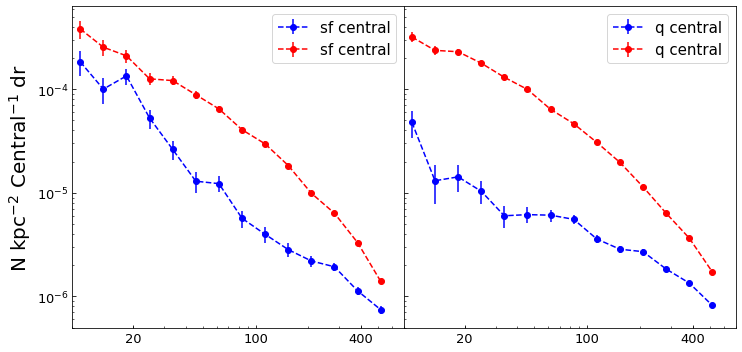

In [26]:
# check galaxy conformity
fig, axs = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(10,5))
sat_masscut=9.5

# subhalos_sf = subhalos[log_ssfr_sats>-11]
# subhalos_q = subhalos[log_ssfr_sats<-11]
radial_csf_ssf,radial_csf_ssf_err, count_csf = radial(sf_central_halos,subhalos,0.0,sat_masscut,13.0,ssfq='ssf')
radial_csf_sq,radial_csf_sq_err, count_csf = radial(sf_central_halos,subhalos,0.0,sat_masscut,13.0,ssfq='sq')

radial_cq_sq,radial_cq_sq_err, count_cq = radial(q_central_halos,subhalos,0.0,sat_masscut,13.0,ssfq='sq')
radial_cq_ssf,radial_cq_ssf_err, count_cq = radial(q_central_halos,subhalos,0.0,sat_masscut,13.0,ssfq='ssf')

axs[0].errorbar(bin_edges[:-1],radial_csf_ssf/areas/count_csf,yerr=radial_csf_ssf_err/areas/count_csf,fmt='ob--',label='sf central')
axs[0].errorbar(bin_edges[:-1],radial_csf_sq/areas/count_csf,yerr=radial_csf_sq_err/areas/count_csf,fmt='or--',label='sf central')

axs[1].errorbar(bin_edges[:-1],radial_cq_ssf/areas/count_cq,yerr=radial_cq_ssf_err/areas/count_cq,fmt='ob--',label='q central')
axs[1].errorbar(bin_edges[:-1],radial_cq_sq/areas/count_cq,yerr=radial_cq_sq_err/areas/count_cq,fmt='or--',label='q central')

axs[0].legend(fontsize=15)
axs[1].legend(fontsize=15)
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_xlim([9,700])
axs[0].set_xticks([20, 100, 400])
axs[0].get_xaxis().set_major_formatter(matplotlib.ticker.ScalarFormatter())
plt.tight_layout()
fig.subplots_adjust(hspace=0)
fig.subplots_adjust(wspace=0)
axs[0].set_ylabel('N kpc$^{-2}$ Central$^{-1}$ dr',fontsize=20)
plt.savefig('conforminty_z0.png')

## Track centrals through redshift
1. list of centrals in SnapNum=N
2. walk back merger tree to SnapNum=N-1
3. find first progenitors (use SubfindID) in SnapNum=N-1
4. repeat to SnapNum = N-2 and so on

In [2]:
basePath = 'sims.TNG/TNG300-1/output/'
last_snap =  99   # z=0

# basePath = './sims.illustris/Illustris-1/output/'
# last_snap = 135
# snap_start = 91

#========================================
header = il.groupcat.loadHeader(basePath,0)
boxsize = header['BoxSize']
track = 'later'

In [35]:
from astropy.coordinates import SkyCoord
import astropy.units as u

# set the radial bins
bin_number = 20

bin_edges = 10 ** np.linspace(1.0, 3.225, num=bin_number+1)  # 10^3.225 = 1628 (in kpc)
areas = np.array([])
for i in range(len(bin_edges[:-1])):
    areas = np.append(areas, (bin_edges[i + 1] ** 2 - bin_edges[i] ** 2) * np.pi)

bin_number = 20
r200_bin_edges = 10 ** np.linspace(-3,1, num=bin_number+1)
r200_areas = np.array([])
for i in range(len(bin_edges[:-1])):
    r200_areas = np.append(r200_areas, (r200_bin_edges[i + 1] ** 2 - r200_bin_edges[i] ** 2) * np.pi)

# load in time,z,snap relation
if 'TNG' in basePath:
    tng_time = Table.read('TNG_snap_time.csv')
    z_list = tng_time['z']
else:
    illustris_time = Table.read('illustris_snap_time.csv')
    z_list = illustris_time['Redshift']

def radial_count(snap, z_list, massive_central_halos, halo_ids,track='prev',save_cats=True):
    z = z_list[snap]
    a = 1/(1+z)
    
    bin_number = 20
    r200_bin_edges = 10 ** np.linspace(-3,1, num=bin_number+1)
    r200_areas = np.array([])
    for i in range(len(bin_edges[:-1])):
        r200_areas = np.append(r200_areas, (r200_bin_edges[i + 1] ** 2 - r200_bin_edges[i] ** 2) * np.pi)
    
    # load subhalos at snap_start
    if snap != snap_start:
        fields = ['SubhaloPos','SubhaloMass','SubhaloStellarPhotometricsMassInRad','SubhaloMassInRadType',
              'SubhaloStellarPhotometrics','SubhaloGrNr','SubhaloSFR']
        subhalos = il.groupcat.loadSubhalos(basePath,snap,fields=fields)
        del subhalos['count']
        subhalos = Table(subhalos)
        subhalos.add_column(Column(data=np.arange(len(subhalos)),name='id'))
        subhalos_cut = subhalos[subhalos['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
    else:
        print('running radial count at snap start', snap_start)
        subhalos = subhalos_start
    
    # satellite galaxy mass cut logM=9.5    
    sat_masscut = 10**(9.5-10)
    subhalos_masscut = subhalos[subhalos['SubhaloMassInRadType'][:,4]>sat_masscut*0.704]  # x*10^10 M_sun / h
    
    tree = KDTree(subhalos_masscut['SubhaloPos'])
    tree_2d = KDTree(subhalos_masscut['SubhaloPos'][:,1:]) # projected 2d kdtree
    
    radial_tot = np.zeros(bin_number)
    massive_count = 0
    on_edge_count = 0
    total_sat_num = 0
    total_merged = 0
    total_not_in_tree = 0
    halo_ids_checked = [] # checked to have satellites and is a central
    
    # massive_central_halos = massive_central_halos[-100:]
    # halo_ids = halo_ids[-100:]
    for i in range(len(massive_central_halos)):
        halo = massive_central_halos[i]
        halo_id = halo_ids[i]
        r200 = halo['Group_R_Crit200']  # comoving kpc / h
        
        # the central galaxy for each halo
        first_subhalo = subhalos[subhalos['id']==halo['GroupFirstSub']][0]
        
        # cut central galaxy that is close to box edge
        central_on_edge = False
        for k in range(3):
            if abs(boxsize/2-first_subhalo['SubhaloPos'][k])>boxsize/2-r200:
                central_on_edge = True
                on_edge_count += 1
        if central_on_edge == True: 
            continue
        
        # exclude halo if its central is more than 10 ckpc/h away from the halo center
        if np.linalg.norm(first_subhalo['SubhaloPos']-halo['GroupPos'])>10: 
            continue
            
        # cut the satellite catalog
        ind = tree_2d.query_radius([first_subhalo['SubhaloPos'][1:]],3*r200,count_only=False) # comoving kpc / h
        cat_neighbors = subhalos_masscut[ind[0]]
        cat_neighbors = cat_neighbors[abs(cat_neighbors['SubhaloPos'][:,0]-first_subhalo['SubhaloPos'][0])<3*r200]
            
        #print(max(abs(cat_neighbors['SubhaloPos'][:,0]-halo['GroupPos'][0])/r200),max(abs(cat_neighbors['SubhaloPos'][:,1]-halo['GroupPos'][1])/r200),max(abs(cat_neighbors['SubhaloPos'][:,2]-halo['GroupPos'][2])/r200))
        
        # isolation criteria
        cat_bright_neighbors = cat_neighbors[cat_neighbors['SubhaloMassInRadType'][:,4]>first_subhalo['SubhaloMassInRadType'][4]]
        if len(cat_bright_neighbors)>=1: 
            print('a more massive companion!','No. of more massive satellites:',len(cat_bright_neighbors))
            continue
        elif len(cat_neighbors)<=1:
            print('no sats!')
            continue
        else:
            halo_ids_checked.append(halo_id)  #halos with isolated massive galaxy (central)
            massive_count += 1
            
        # remove central from cat_neighbors
        max_mass_index = np.argmax(cat_neighbors['SubhaloMassInRadType'][:,4]) # index of central in catneighbors
        cat_neighbors = np.delete(cat_neighbors, max_mass_index) # remove central from cat_neighbors

        # keep record of satellites and their fate of this halo and their progenitors/decendants
        if save_cats == True:
            if track == 'prev': # track back in time
                cat_neighbors_survived = sat_prev(halo_id, z, cat_neighbors,snap_start=snap,snap_end=snap_end,halo=halo)
            elif track == 'later': # track foward in time
                cat_neighbors_survived, merged, disrupted, not_in_tree = sat_later(halo_id, z, cat_neighbors, snap_start=snap,snap_end=snap_end,halo=halo,r200=float(r200))
                total_sat_num += len(cat_neighbors)
                total_merged += merged # merged at snap_end
                total_not_in_tree += not_in_tree
                
            if len(cat_neighbors_survived)==0:
                print(halo_id,'no survived sats!')
                continue
            
        # calculation (2D selection for radial distribution)
        radial = []        
        subtree = KDTree(cat_neighbors['SubhaloPos'][:,1:])
        for bin_edge in r200_bin_edges:
            ind = subtree.query_radius([halo['GroupPos'][1:]],bin_edge/a*0.704,count_only=True) # comoving kpc / h
            radial.append(ind[0])
        
        radial = np.diff(np.array(radial))
        radial_tot += radial
    
    print('massive gals:',len(massive_central_halos),', isolated centrals:',massive_count,', on edge:',on_edge_count)
    print('Number counts for satellites. Survived:',total_sat_num,'Merged:',total_merged, 'Skippped snaps',disrupted,'Not in tree:',total_not_in_tree)
    return radial_tot, massive_count, halo_ids_checked


# keep track of satellites in previous snapshots
def sat_prev(halo_id, z, cat_neighbors, snap_start, snap_end, halo):
    sat_ids = cat_neighbors['id']
    sat_prev_tot_ids = np.ones(snap_start-snap_end)
    mask = []
    for i, sat_id in enumerate(sat_ids):
        sat_prev = il.sublink.loadTree(basePath,snap_start,sat_id,fields=['SubfindID','SnapNum'],onlyMPB=True)
        if sat_prev != None: # the satellite is in a tree
            sat_prev_ids = sat_prev['SubfindID'][:snap_start-snap_end]
            if sat_prev_tot_ids.shape[-1]==len(sat_prev_ids): # satellite has progenitor up to snap_end
                sat_prev_tot_ids = np.vstack([sat_prev_tot_ids, sat_prev_ids])
                mask.append(True)
            else: 
                mask.append(False)
        else:
            mask.append(False)
    
    cat_neighbors = cat_neighbors[mask]
    cat_neighbors['SubhaloSFR'][cat_neighbors['SubhaloSFR']==0.0] = 1e-5
    cat_logssfr = np.log10(cat_neighbors['SubhaloSFR']/1e10/0.704/cat_neighbors['SubhaloMassInRadType'][:,4])
    sat_prev_tot_ids = sat_prev_tot_ids[1:]
    
    # record distance list at snap_start
    distance_list(snap_start, z, cat_neighbors, halo['GroupPos'][1:],halo_id, sat_ids, save_dir='sat_catalogs/')
    distance_list_3d(snap_start, z, cat_neighbors, halo['GroupPos'],halo_id, sat_ids, save_dir='sat_catalogs/')
    
    # record id in later snapshots
    np.save('sat_catalogs/'+str(halo_id)+'_logssfr_sats.npy',cat_logssfr)
    np.save('sat_catalogs/'+str(halo_id)+'_sats.npy',sat_prev_tot_ids)
    
    # return cat_neighbors in snap_start
    if len(cat_neighbors)>0:
        return cat_neighbors
    else:
        return np.array([])
    

# keep track of satellites in later snapshots
def sat_later(halo_id, z, cat_neighbors, snap_start, snap_end, halo,r200=''):
    # print(halo_id)
    sat_ids = cat_neighbors['id']
    # print(halo_id,min(cat_neighbors['SubhaloMassInRadType'][:,4]))
    sat_later_tot_ids = np.array([np.ones(snap_end-snap_start+1)])
    
    mask = [] 
    mask_merged = []
    merged_list = []
    disrupted_list = []
    not_in_tree = 0
    for i, sat_id in enumerate(sat_ids): 
        sat_later = il.sublink.loadTree(basePath,snap_start,sat_id,fields=['SubfindID','SnapNum'],onlyMDB=True)  # tracking of satellites
        if sat_later != None: # the satellite is in a tree
            if len(sat_later['SubfindID'])!= abs(snap_start-last_snap):  # last_snap=99 for TNG and 135 for il
                mask.append(False)
                
                # if get the full merger tree --> merged (before last_snap) satellites
                if len(sat_later['SubfindID'])> abs(snap_start-last_snap):
                    merged_list.append(sat_id)
                    mask_merged.append(True)
                
                # if MDB skip a few snaps (may be disrupted satellites)
                else:
                    disrupted_list.append(sat_id)
                    mask_merged.append(False)
            
            # survived satellites
            else:
                mask_merged.append(False)
                sat_later_ids = sat_later['SubfindID'][snap_start-snap_end:]
                
                if sat_later_tot_ids.shape[-1]==len(sat_later_ids)+1:  # satellite has decendant until snap_end
                    sat_later_tot_ids = np.vstack([sat_later_tot_ids, np.append(sat_id,np.flip(sat_later_ids,axis=0))])
                    mask.append(True)
                else: 
                    mask.append(False)
                    
        # the satellite is NOT in a tree      
        else: 
            mask.append(False)
            mask_merged.append(False)
            not_in_tree += 1
    
    cat_merged = cat_neighbors[mask_merged]  # catalog of merged satellites (before last_snap)
    cat_neighbors = cat_neighbors[mask]  # catalog of survived satellites
    cat_neighbors['SubhaloSFR'][cat_neighbors['SubhaloSFR']==0.0] = 1e-5
    cat_logssfr = np.log10(cat_neighbors['SubhaloSFR']/(cat_neighbors['SubhaloMassInRadType'][:,4]*1e10/0.704))
    
    # if len(cat_merged)>1:
    #     print(max(abs(cat_merged['SubhaloPos'][:,0]-halo['GroupPos'][0])/r200),max(abs(cat_merged['SubhaloPos'][:,1]-halo['GroupPos'][1])/r200),max(abs(cat_merged['SubhaloPos'][:,2]-halo['GroupPos'][2])/r200))
    
    # record distance list at snap_start
    # record distance in terms of R200

    distance_list(snap_start, z, cat_neighbors, halo['GroupPos'][1:],halo_id,sat_ids, r200=float(r200), save_dir='sat_catalogs_later/')  # projected 2D distance
    distance_list_3d(snap_start, z, cat_neighbors, halo['GroupPos'],halo_id,sat_ids, r200=float(r200), save_dir='sat_catalogs_later/')   # 3D distance
    distance_list_3d(snap_start, z, cat_merged, halo['GroupPos'],halo_id,merged_list, r200=float(r200), save_dir='sat_catalogs_later/',sat_type='_merged')  # 3D distance
    
    # record id in later snapshots
    sat_later_tot_ids = sat_later_tot_ids[1:]
    np.save('sat_catalogs_later/'+str(halo_id)+'_merged_sats.npy',merged_list)
    np.save('sat_catalogs_later/'+str(halo_id)+'_disrupted_sats.npy',disrupted_list)
    np.save('sat_catalogs_later/'+str(halo_id)+'_logssfr_sats.npy',cat_logssfr) # ssfr for survived sats
    np.save('sat_catalogs_later/'+str(halo_id)+'_sats.npy',sat_later_tot_ids)  # survived sat ids
    
    # return cat_neighbors in snap_start
    return cat_neighbors, len(merged_list), len(disrupted_list), not_in_tree
    

def read_satellite_cat(subhalos, halo_id_start, snap, snap_start, save_dir):
    sat_ids = np.load(save_dir+str(halo_id_start)+'_sats.npy')
    if len(sat_ids.shape)==2:
        sat_ids_this_snap = sat_ids[:,abs(snap_start-snap)]
        sat_ids_snap_start = sat_ids[:,0]
        sat_cat = subhalos[sat_ids_this_snap.astype(int)]
        return sat_cat, sat_ids_snap_start
    
    else:
        print('no satellites for:',halo_id_start)
        return np.array([]), np.array([])
    

def radial_count_prev(snap, z_list, halo_ids_start, halo_ids, halo_ids_start_checked, subhalos,r200_list):
    
    bin_number = 20
    r200_bin_edges = 10 ** np.linspace(-3,1, num=bin_number+1)
    r200_areas = np.array([])
    for i in range(len(bin_edges[:-1])):
        r200_areas = np.append(r200_areas, (r200_bin_edges[i + 1] ** 2 - r200_bin_edges[i] ** 2) * np.pi)
    
    z = z_list[snap]
    a = 1/(1+z) # scale factor
    radial_tot = np.zeros(len(r200_bin_edges)-1)
    
    halo_sat_saved_number = 0
    for i in range(len(halo_ids)):
        halo_id_start = halo_ids_start[i] # halo ids at snap_start
        halo_id = halo_ids[i] # halo ids at the current snap
        r200 =  r200_list[i]*a/0.704 # at current snap (physical kpc)
        
        # load halo
        save_dir = 'sat_catalogs/' if track=='prev' else 'sat_catalogs_later/'
        halo = il.groupcat.loadSingle(basePath,snap,haloID=halo_id)
        
        # check if central galaxy of this halo satisfies all criteria
        if halo_id_start not in halo_ids_start_checked:
            try:
                os.system('rm '+save_dir+'/distance_list_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')
            except FileNotFoundError:
                pass
            
            continue
            
        # read in satellite catalogs in this snapshot
        try:
            sat_cat, sat_ids_start = read_satellite_cat(subhalos, halo_id_start, snap, snap_start, save_dir=save_dir)
            if len(sat_cat)==0: 
                print('no sat for halo '+str(halo_id_start)+' (id at snap_start)')
                continue
            elif len(sat_cat) != len(sat_ids_start):
                print('no. of sat do not match between snaps')
                continue
                
        except FileNotFoundError:
            print(halo_id_start,'not found')
            continue
        
        # save distance list for satellites at current snap
        distance_list(snap, z, sat_cat, halo['GroupPos'][1:], halo_id_start, sat_ids_start, save_dir=save_dir,r200=float(r200))
        distance_list_3d(snap, z, sat_cat, halo['GroupPos'], halo_id_start, sat_ids_start, save_dir=save_dir,r200=float(r200))
        halo_sat_saved_number += 1
        
        # the calculation
        radial = []
        subtree = KDTree(sat_cat['SubhaloPos'][:,1:])  # ready for 2d spatial selection
        for bin_edge in bin_edges:
            ind = subtree.query_radius([halo['GroupPos'][1:]],bin_edge/a*0.704,count_only=True) # comoving kpc / h
            radial.append(ind[0])
            
        radial = np.diff(np.array(radial))
        radial_tot += radial
    
    print('satellite distance saved for '+ str(halo_sat_saved_number)+' halos.')
    return radial_tot, massive_count



In [39]:
def distance_list(snap, z, cat_sat, central_coord, halo_id, sat_ids_start, r200='',save_dir = 'sat_catalogs/'):
    a = 1/(1+z)
    cat_sat_x = cat_sat['SubhaloPos'][:,1]
    cat_sat_y = cat_sat['SubhaloPos'][:,2]
    central_x = central_coord[0]
    central_y = central_coord[1]
    
    distance_list = []
    for i in range(len(cat_sat)):
        dx = abs(cat_sat_x[i]-central_x)
        dy = abs(cat_sat_y[i]-central_y)
        
        if dx > boxsize/2: dx = boxsize - dx
        if dy > boxsize/2: dy = boxsize - dy
        distance = np.sqrt(dx**2+dy**2)*a/0.704 # in kpc (physical) 
        
        if isinstance(r200,float):
            distance = distance/(r200*a/0.704)
        distance_list.append(distance)
        
    np.save(save_dir+'distance_list_'+str(snap)+'_'+str(halo_id)+'.npy',np.array(distance_list))
    return distance_list


def distance_list_3d(snap, z, cat_sat, central_coord_3d, halo_id, sat_ids_start,  r200='', save_dir='sat_catalogs/',sat_type=''):
    a = 1/(1+z)
    cat_sat_x = cat_sat['SubhaloPos'][:,1]
    cat_sat_y = cat_sat['SubhaloPos'][:,2]
    cat_sat_z = cat_sat['SubhaloPos'][:,0]
    central_x = central_coord_3d[1]                       
    central_y = central_coord_3d[2]
    central_z = central_coord_3d[0]
    
    distance_list = []
    sat_ejected_ids = []
    for i in range(len(cat_sat)):
        dx = abs(cat_sat_x[i]-central_x)
        dy = abs(cat_sat_y[i]-central_y)
        dz = abs(cat_sat_z[i]-central_z)
        
        if dx > boxsize/2: dx = boxsize - dx
        if dy > boxsize/2: dy = boxsize - dy
        if dz > boxsize/2: dz = boxsize - dz
        distance = np.sqrt(dx**2+dy**2+dz**2)*a/0.704 # in kpc (physical) 
        
        if isinstance(r200,float):
            distance = distance/(r200*a/0.704)
        distance_list.append(distance)
        
        if distance>1e4:
            sat_ejected_ids.append(sat_ids_start[i])

    if save_dir[-1]=='/':
        np.save(save_dir+'distance_list'+sat_type+'_3d_'+str(snap)+'_'+str(halo_id)+'.npy',np.array(distance_list))
        if len(sat_ejected_ids) > 0:
            np.save(save_dir+'ejected_id_list_3d_'+str(snap)+'_'+str(halo_id)+'.npy',np.array(sat_ejected_ids))
    else:
        print('save_dir '+save_dir+' does not end in "/" !')
    
    return distance_list

def distance_list_proj_lite(snap, z, sat_coords, central_coord_3d, r200='', proj_collapse=0, save_dir='sat_catalogs_later/'):
    a = 1/(1+z)
    cat_sat_x = sat_coords[:,1]
    cat_sat_y = sat_coords[:,2]
    cat_sat_z = sat_coords[:,0]
    central_x = central_coord_3d[1]                       
    central_y = central_coord_3d[2]
    central_z = central_coord_3d[0]
    
    distance_list = []
    for i in range(len(cat_sat_x)):
        dx = abs(cat_sat_x[i]-central_x)
        dy = abs(cat_sat_y[i]-central_y)
        dz = abs(cat_sat_z[i]-central_z)
        
        if dx > boxsize/2: dx = boxsize - dx
        if dy > boxsize/2: dy = boxsize - dy
        if dz > boxsize/2: dz = boxsize - dz
        
        if proj_collapse==0:
            distance = np.sqrt(dx**2+dy**2)*a/0.704  # in kpc (physical) 
        elif proj_collapse==1:
            distance = np.sqrt(dy**2+dz**2)*a/0.704  # in kpc (physical)
        elif proj_collapse==2:
            distance = np.sqrt(dx**2+dz**2)*a/0.704  # in kpc (physical)
        
        if isinstance(r200,float):
            distance = distance/(r200*a/0.704) # both in physical kpc
            
        distance_list.append(distance)

    return distance_list


def distance_list_3d_lite(snap, z, sat_coords, central_coord_3d, r200='', save_dir='sat_catalogs_later/'):
    a = 1/(1+z)
    cat_sat_x = sat_coords[:,1]
    cat_sat_y = sat_coords[:,2]
    cat_sat_z = sat_coords[:,0]
    central_x = central_coord_3d[1]                       
    central_y = central_coord_3d[2]
    central_z = central_coord_3d[0]
    
    distance_list = []
    for i in range(len(cat_sat_x)):
        dx = abs(cat_sat_x[i]-central_x)
        dy = abs(cat_sat_y[i]-central_y)
        dz = abs(cat_sat_z[i]-central_z)
        
        if dx > boxsize/2: dx = boxsize - dx
        if dy > boxsize/2: dy = boxsize - dy
        if dz > boxsize/2: dz = boxsize - dz
            
        distance = np.sqrt(dx**2+dy**2+dz**2)*a/0.704  # in kpc (physical) 
        
        if isinstance(r200,float):
            distance = distance/(r200*a/0.704)
        distance_list.append(distance)

    return distance_list

def distance_list_3d_single(snap, z, sat_coord, central_coord_3d):
    a = 1/(1+z)
    sat_x = sat_coord[1]
    sat_y = sat_coord[2]
    sat_z = sat_coord[0]
    central_x = central_coord_3d[1]                       
    central_y = central_coord_3d[2]
    central_z = central_coord_3d[0]
    
    dx = abs(sat_x-central_x)
    dy = abs(sat_y-central_y)
    dz = abs(sat_z-central_z)
        
    if dx > boxsize/2: dx = boxsize - dx
    if dy > boxsize/2: dy = boxsize - dy
    if dz > boxsize/2: dz = boxsize - dz
            
    distance = np.sqrt(dx**2+dy**2+dz**2)*a/0.704  # in kpc (physical) 
    return distance

In [33]:
# read in halo and subhalo catalogs ( at snap_start )
# snap_start = 50   # z=1.0
# snap_end =   72   # z=0.4

# snap_start = 72   # z=0.4
# snap_end =   91   # z=0.1

snap_start = 61   # z=0.65
snap_end =   75   # z=0.35

# snap_start = 51   # z=0.95
# snap_end =   61   # z=0.65

# snap_start = 43   # z=1.3
# snap_end =   51   # z=0.95

# read in halo and subhalo catalogs ( at snap_start )
print('snap_start:',snap_start)
print('snap_end:',snap_end)
print(basePath)

# load halos (groups) at snap_start
print('loading halos')
halos_start = il.groupcat.loadHalos(basePath,snap_start,fields=['GroupFirstSub','GroupPos','Group_M_Crit200','Group_R_Crit200','GroupNsubs'])
del halos_start['count']
halos_start = Table(halos_start)
halos_start.add_column(Column(data=np.arange(len(halos_start)),name='id'))
halos_start = halos_start[halos_start['Group_M_Crit200']>10*0.704] #10**11 solar masses
halos_start.write('halos_start_'+str(snap_start)+'.fits',overwrite=True)
print('Halos loaded')

# load subhalos at snap_start
print('loading subhalos')
fields = ['SubhaloPos','SubhaloMass','SubhaloStellarPhotometricsMassInRad','SubhaloMassInRadType','SubhaloStellarPhotometrics','SubhaloGrNr','SubhaloSFR']
subhalos_start = il.groupcat.loadSubhalos(basePath,snap_start,fields=fields)
del subhalos_start['count']
subhalos_start = Table(subhalos_start)
subhalos_start.add_column(Column(data=np.arange(len(subhalos_start)),name='id'))
subhalos_start = subhalos_start[subhalos_start['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
subhalos_start.write('subhalos_start_'+str(snap_start)+'.fits',overwrite=True)
print('Subhalos loaded')

snap_start: 61
snap_end: 75
sims.TNG/TNG300-1/output/
loading halos
Halos loaded
loading subhalos
Subhalos loaded


In [34]:
halos_start.write('halos_start_'+str(snap_start)+'.fits',overwrite=True)
subhalos_start.write('subhalos_start_'+str(snap_start)+'.fits',overwrite=True)
print('halos:',len(halos_start))
print('subhalos:',len(subhalos_start))

halos: 311871
subhalos: 625311


### Find progenitors/decendants

In [36]:
# select halos with massive central galaxies at snap_start
halos_start = Table.read('halos_start_'+str(snap_start)+'.fits')
subhalos_start = Table.read('subhalos_start_'+str(snap_start)+'.fits')

print(len(halos_start))
masscut_central_low = 10**(11.3-10) if track=='prev' else 10**(11.2-10) # in 10^10 M_sun
masscut_central_high = 10**(11.5-10) if track=='prev' else 10**(11.5-10) # in 10^10 M_sun

cond=np.in1d(subhalos_start['id'], halos_start['GroupFirstSub'])
first_subhalos_start = subhalos_start[cond]
cond2=np.in1d(halos_start['GroupFirstSub'],subhalos_start['id'])
halos_start = halos_start[cond2]

print(len(halos_start),len(first_subhalos_start))

massive_central_halos_start = halos_start[np.logical_and(first_subhalos_start['SubhaloMassInRadType'][:,4]>masscut_central_low*0.704,first_subhalos_start['SubhaloMassInRadType'][:,4]<masscut_central_high*0.704)]
# massive_central_halos_start = halos_start[first_subhalos_start['SubhaloMassInRadType'][:,4]>masscut_central_low*0.704]

central_ids_start = massive_central_halos_start['GroupFirstSub']
halo_ids_start = massive_central_halos_start['id']
print('number of massive gals (possible centrals):',len(central_ids_start))


311871
292471 292471
number of massive gals (possible centrals): 826


In [37]:
# descendants of centrals selected at snap_start
# list of centrals and their ID in later snapshots

print('snap_start:',snap_start)
print('snap_end:',snap_end)
len_descendants = abs(snap_start-snap_end)+1
descendants = np.ones(len_descendants)
mask = []
for i in tqdm(range(len(central_ids_start))):
    central_id = central_ids_start[i]
    merger_tree = il.sublink.loadTree(basePath,snap_start,central_id,fields=['SnapNum','SubfindID'],onlyMDB=True) #only Main Decendent branch
    if merger_tree != None:   
        # cut off centrals that don't have right length of MDB.
        if len(merger_tree['SubfindID'])>len_descendants and merger_tree['SnapNum'][-len_descendants]-merger_tree['SnapNum'][-1]==abs(snap_start-snap_end):
            descendants = np.vstack([descendants, np.append(central_id, np.flip(merger_tree['SubfindID'][-abs(snap_start-snap_end):],axis=0))])
            mask.append(True)
        else:
            mask.append(False)
    else:
        print('merger tree is None.')

descendants = descendants[1:].astype(int)
print(descendants.shape)

# mask the selection
central_ids_start = central_ids_start[mask].astype(int)
halo_ids_start = halo_ids_start[mask].astype(int)
massive_central_halos_start = massive_central_halos_start[mask]

if len(central_ids_start) != len(halo_ids_start) or len(halo_ids_start) != len(massive_central_halos_start):
    raise Exception('central,halo_id, central_id do not have the same length!')

snap_start: 61
snap_end: 75


100%|██████████| 826/826 [01:08<00:00, 12.11it/s]

(799, 15)


#### calculate radial number density

In [40]:
# calculate radial number density at snap_start
massive_counts = []
radial_z = np.zeros(bin_number)
                    
# snaps = np.arange(snap_start,snap_end,-5) if track =='prev' else np.arange(snap_start,snap_end,5)
snaps = np.array([snap_start, snap_end])
print(track,snaps)

# calculate number density profile at snap_start
radial_tot_z, massive_count,halo_ids_start_checked = radial_count(snap_start, z_list, massive_central_halos_start,halo_ids_start,track=track)
radial_z = np.vstack([radial_z,radial_tot_z]) # stack results for each snapshot 
massive_counts.append(massive_count)

#######################################
# track centrals and sats in later snaps
for snap in snaps[1:]:
    print('===SnapNum:',snap)
    
    # load halos at this snap
    halos = il.groupcat.loadHalos(basePath,snap,fields=['GroupFirstSub','GroupPos','Group_R_Crit200'])
    del halos['count']
    halos = Table(halos)
    
    # load subhalos at this snap
    subhalos = il.groupcat.loadSubhalos(basePath,snap,fields=['SubhaloGrNr','SubhaloPos'])
    del subhalos['count']
    subhalos = Table(subhalos)
    
    # find the progenitors/decendants of centrals and the halos they live in
    # selected in snap_start but use IDs in current snapshot
    central_ids = progenitors[:, snap_start - snap] if track =='prev' else descendants[:, snap - snap_start]
    halo_ids = np.array(subhalos[central_ids]['SubhaloGrNr']) # halo ids at the current snap
    r200_list = halos[halo_ids]['Group_R_Crit200'] #ckpc/h
    massive_central_halos = halos[halo_ids]
    
    # calculate number density profile
    radial_tot_z, massive_count = radial_count_prev(snap, z_list,  halo_ids_start, halo_ids, halo_ids_start_checked, subhalos, r200_list)
    radial_z = np.vstack([radial_z, radial_tot_z]) # stack results for each snapshot 
    massive_counts.append(massive_count)

# radial_z is collection of the radial distribution at all snaps
radial_z = radial_z[1:]

running radial count at snap start 61
Warning, empty return. Subhalo [56832] at snapNum [61] not in tree.
Warning, empty return. Subhalo [69822] at snapNum [61] not in tree.
Warning, empty return. Subhalo [69833] at snapNum [61] not in tree.
a more massive companion! No. of more massive satellites: 2
Warning, empty return. Subhalo [116315] at snapNum [61] not in tree.
a more massive companion! No. of more massive satellites: 1
a more massive companion! No. of more massive satellites: 1
a more massive companion! No. of more massive satellites: 1
a more massive companion! No. of more massive satellites: 1
Warning, empty return. Subhalo [143669] at snapNum [61] not in tree.
Warning, empty return. Subhalo [143640] at snapNum [61] not in tree.
Warning, empty return. Subhalo [143652] at snapNum [61] not in tree.
Warning, empty return. Subhalo [143662] at snapNum [61] not in tree.
a more massive companion! No. of more massive satellites: 1
Warning, empty return. Subhalo [146235] at snapNum [6

rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_46.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_109.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_120.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_124.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_127.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_144.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_226.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_234.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_307.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_331.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_lis

no sat for halo 1127 (id at snap_start)


rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_1187.npy': No such file or directory
rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_1867.npy': No such file or directory


no sat for halo 2839 (id at snap_start)
no sat for halo 3211 (id at snap_start)


rm: cannot remove 'sat_catalogs_later//distance_list_3d_61_2882.npy': No such file or directory


no sat for halo 3281 (id at snap_start)
no sat for halo 3332 (id at snap_start)
satellite distance saved for 773 halos.


In [44]:
arr = np.load('sat_catalogs_later/distance_list_61_30.npy')
print(arr)

[1.03396728 0.96097337 1.06160012 0.84586851 1.01297093 0.92929043
 0.50005969 2.30334354 1.24301311 1.42199447 0.77151307 0.81235954
 2.67951104 0.40370196 0.39558064 0.43396945 0.62901801 0.60204945
 0.36963122 0.96590534 0.32845598 1.54305744 0.848457   0.91105809
 0.98962555 1.06678474 1.33110863 1.18362946 1.05562437 0.47463484
 1.35096714 0.85071077 2.22528799 2.01101298 2.02617721 2.01133414
 1.99026191 1.73402265 1.98952168 2.05670434 2.97245403 0.99038502
 0.96699503 0.09357162 0.3146259  0.3955515  0.14477463 0.09971026
 1.26624234 1.24306686]


5640


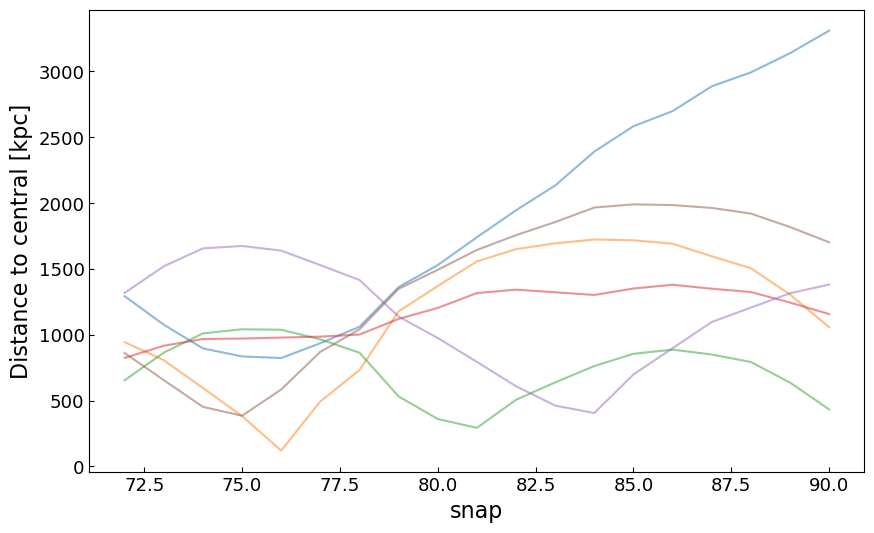

In [48]:
# distance change (in one example)
tng_time = Table.read('TNG_snap_time.csv')
save_dir = 'sat_catalogs/' if track=='prev' else 'sat_catalogs_later/'
fig, axs = plt.subplots(1, 1, figsize=(10, 6))

snaps=np.arange(snap_start,snap_end,1)
for halo_id in halo_ids_start[1:2]:
    central_id = halos_start[halo_id]['GroupFirstSub']
    survived_sat_ids = np.load(save_dir+str(halo_id)+'_sats.npy')
    print(central_id)
    if central_id in descendants: 
        for sat_id_snaps in survived_sat_ids[:6]:
            distance_list=[]
            for snap in snaps:
                sat_id_current = int(sat_id_snaps[snap-snap_start])
                sat = il.groupcat.loadSingle(basePath, snap, subhaloID=sat_id_current)
                descendant_id = descendants[descendants[:,0]==central_id][0][snap-snap_start]
                central = il.groupcat.loadSingle(basePath, snap, subhaloID=descendant_id)
                distance_list.append(distance_list_3d_single(snap, tng_time[snap]['z'], sat['SubhaloPos'], central['SubhaloPos']))
            
            plt.plot(snaps,distance_list,alpha=0.5)

plt.xlabel('snap',fontsize=16)
plt.ylabel('Distance to central [kpc]',fontsize=16)
plt.savefig('distance_change_one_halo.png')

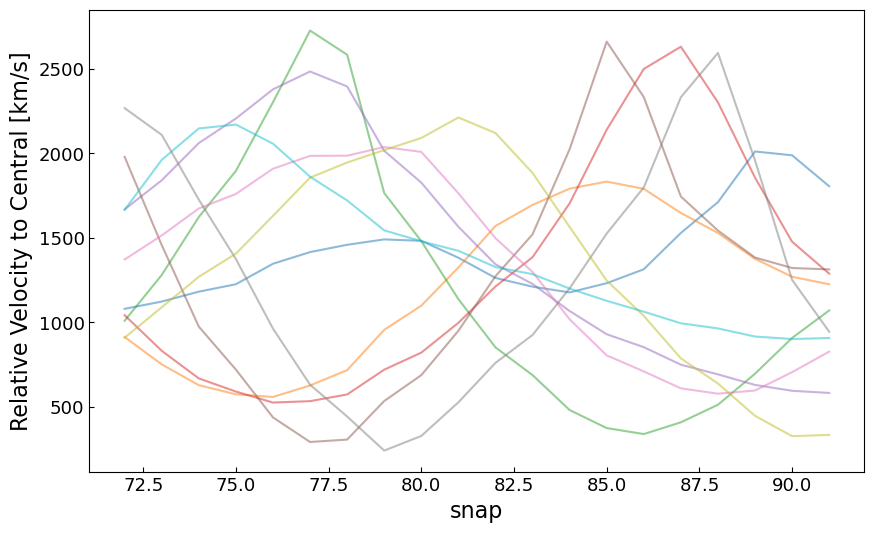

In [50]:
#velocity change (in one example)
save_dir = 'sat_catalogs/' if track=='prev' else 'sat_catalogs_later/'
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 6))

snaps=np.arange(snap_start,snap_end+1,1)
for halo_id in halo_ids_start[2:3]:
    central_id = halos_start[halo_id]['GroupFirstSub']
    survived_sat_ids = np.load(save_dir+str(halo_id)+'_sats.npy')
    if central_id in descendants: 
        for sat_id_snaps in survived_sat_ids[:10]:
            velocity_list=[]
            for snap in snaps:
                sat_id_current = int(sat_id_snaps[snap-snap_start])
                sat = il.groupcat.loadSingle(basePath, snap, subhaloID=sat_id_current)
                descendant_id = descendants[descendants[:,0]==central_id][0][snap-snap_start]
                central = il.groupcat.loadSingle(basePath, snap, subhaloID=descendant_id)
                velocity_list.append(np.sqrt(sum(((sat['SubhaloVel']-central['SubhaloVel'])**2))))
            
            plt.plot(snaps,velocity_list,alpha=0.5) 
            
plt.xlabel('snap',fontsize=16)
plt.ylabel('Relative Velocity to Central [km/s]',fontsize=16)
plt.savefig('velocity_change_one_halo.png')

### Fate of satellite galaxies

In [9]:
# find out the fate for merged satellites (merged with centrals before or after snap_end, or merged with other?)
# only work for track == 'later'

total_merged = 0
total_merged_with_central = 0
tng_time = Table.read('TNG_snap_time.csv')
print('number of halos to track:',len(halo_ids_start_checked))

for i in tqdm(range(len(halo_ids_start_checked))):
    halo_id = halo_ids_start_checked[i]
    central_id = halos_start[halos_start['id']==halo_id]['GroupFirstSub'][0]
    r200 =  halos_start[halos_start['id']==halo_id][0]['Group_R_Crit200']
    
    try:
        merged_sat_ids = np.load('sat_catalogs_later/'+str(halo_id)+'_merged_sats.npy')
    except FileNotFoundError:
        continue
        
    # look into central galaxies' merger tree
    if central_id in descendants:
        central_mdb = il.sublink.loadTree(basePath,snap_start,central_id,fields=['SnapNum','SubfindID'],onlyMDB=True)
        descendant_id = descendants[descendants[:,0]==central_id][0][-1]
        root_descendant_id = central_mdb['SubfindID'][0]
        
        # full merger trees of central decendant
        full_tree_root = il.sublink.loadTree(basePath,99,root_descendant_id,fields=['SnapNum','SubfindID'])
        full_tree      = il.sublink.loadTree(basePath,snap_start+descendants.shape[1]-1,descendant_id,fields=['SnapNum','SubfindID'])
        
        subfind_IDs_root = full_tree_root['SubfindID']
        subfind_IDs = full_tree['SubfindID']
        merged_with_central = []
        merged_with_central_root = []
        merged_sat_ids_cen = []
        merged_sat_ids_cen_root = []
        distance_merged_cen_list = []
        distance_merged_cen_root_list = []
                
        central_start = subhalos_start[subhalos_start['id']==central_id][0]
        for sat_id in merged_sat_ids:
            if sat_id in subfind_IDs_root:
                sat = subhalos_start[subhalos_start['id']==sat_id][0] 
                distance = abs(sat['SubhaloPos'][0]-central_start['SubhaloPos'][0])/r200
                if distance>3:
                    print(central_id,sat_id,distance)
        
                ind = np.where(full_tree_root['SubfindID']==sat_id)  # look for satellite id in central's root decendant
                
                # if found the satellite subfindID at the correct snapshot
                if len(ind[0])==1 and full_tree_root['SnapNum'][ind[0][0]]==snap_start:
                    diff = 1 # next_snap - current_snap
                    index = ind[0][0]
                    current_snap = full_tree_root['SnapNum'][index]
                    # track the satellite until it merges
                    while diff<3 and diff>0 and current_snap<snap_end:
                        current_snap = full_tree_root['SnapNum'][index]
                        next_snap = full_tree_root['SnapNum'][index-1]
                        diff= next_snap - current_snap
                        index -= 1
#                     distance_later = distance_list_3d_single(current_snap, tng_time[current_snap]['z'], sat['SubhaloPos'], central['SubhaloPos'])

                    # if merged with central before snap_end
                    if sat_id in subfind_IDs: # merge with central galaxy before snap_end
                        # now current snap is when the satellite last seen in simulation
                        sat_id_current = full_tree_root['SubfindID'][index+1]
                        sat = il.groupcat.loadSingle(basePath, current_snap, subhaloID=sat_id_current)
                        central_id_current = descendants[descendants[:,0]==central_id][0][current_snap-snap_start]
                        central = il.groupcat.loadSingle(basePath, current_snap, subhaloID=central_id_current)
                        merged_sat_ids_cen.append(sat_id)
                        merged_with_central.append(sat_id)  
#                         distance_merged_cen_list.append(distance_later)
                    # merge with central galaxy after snap_end
                    else:                     
                        merged_sat_ids_cen_root.append(sat_id)
                        merged_with_central_root.append(sat_id)
#                         distance_merged_cen_root_list.append(distance_later)
    
        np.save('sat_catalogs_later/'+str(halo_id)+'_merged_with_central_sats.npy',np.array(merged_with_central))
        np.save('sat_catalogs_later/'+str(halo_id)+'_merged_with_central_root_sats.npy',np.array(merged_with_central_root))
        
        # distance for merged_cen sats at earlier time
#         distance_list_3d(snap_start, tng_time[snap_start]['z'],
#                          subhalos_start[np.in1d(subhalos_start['id'],merged_sat_ids_cen)], subhalos_start[subhalos_start['id']==central_id]['SubhaloPos'][0], 
#                          halo_id, merged_sat_ids_cen, save_dir='sat_catalogs_later/',type='_merged_central')
        
#         distance_list_3d(snap_start, tng_time[snap_start]['z'],
#                          subhalos_start[np.in1d(subhalos_start['id'],merged_sat_ids_cen_root)], subhalos_start[subhalos_start['id']==central_id]['SubhaloPos'][0], 
#                          halo_id, merged_sat_ids_cen_root, save_dir='sat_catalogs_later/',type='_merged_central_root')
       
        # distance for merged_cen sats at later time
#         np.save('sat_catalogs_later/distance_'+str(halo_id)+'merged_with_central_sats.npy',np.array(distance_merged_cen_list))
#         np.save('sat_catalogs_later/distance_'+str(halo_id)+'merged_with_central_root_sats.npy',np.array(distance_merged_cen_root_list))
        
        total_merged += len(merged_sat_ids)
        total_merged_with_central += len(merged_with_central)
    else:
        print(central_id,'no match')
        
print(total_merged, total_merged_with_central, total_merged_with_central/total_merged)

number of halos to track: 778


100%|██████████| 778/778 [03:52<00:00,  3.34it/s]

2062 608 0.2948593598448109


In [10]:
# distance distribution (at snap_start) of merged/survived/disrupted satellite galaxies (at snap_end)
bin_number = 20

distances_merged_list = np.array([])
distances_cen_list = np.array([])
distances_survived_list = np.array([])
distances_dpd_list = np.array([])

mass_survived_list = np.array([])
mass_merged_list = np.array([])
mass_cen_list = np.array([])
survived_hm,survived_lm,merged_hm,merged_lm=0,0,0,0

save_dir = 'sat_catalogs_later/'
for i in tqdm(range(len(halo_ids_start_checked))):
    a = 1/(1+tng_time[snap_start]['z']) # scale factor
    halo_id = halo_ids_start_checked[i]
    central_id = halos_start[halo_id]['GroupFirstSub']
    halo_r200 = halos_start[halo_id]['Group_R_Crit200']*a/0.704 #h=0.704 in kpc (physical)
    
    try:
        survived_sat_ids = np.load(save_dir+str(halo_id)+'_sats.npy')
        survived_sat_ids = survived_sat_ids[:,0].astype(int)
        merged_sat_ids = np.load(save_dir+str(halo_id)+'_merged_sats.npy')
        merged_sat_cen_ids = np.load(save_dir+str(halo_id)+'_merged_with_central_sats.npy')
        merged_sat_cen_root_ids = np.load(save_dir+str(halo_id)+'_merged_with_central_root_sats.npy')
        survived_sat_ids = np.append(survived_sat_ids, merged_sat_cen_root_ids).astype(int)
        
        # remove duplicate (merged_sat_ids only contains merged with others)
        duplicate_ids = []
        for i,idx in enumerate(merged_sat_ids):
            if (idx in merged_sat_cen_ids) or (idx in merged_sat_cen_root_ids):
                duplicate_ids.append(i)
        merged_sat_ids = np.delete(merged_sat_ids, duplicate_ids)
        disrupted_ids = np.load(save_dir+str(halo_id)+'_disrupted_sats.npy')
        
    except FileNotFoundError:
        print('file not found')
        continue
    
    central_pos = subhalos_start[subhalos_start['id']==central_id]['SubhaloPos'][0] 
    
    sat_hm_masscut = 10**(10.2-10)
    mass_show = 'all'
    mass_sats_survived = subhalos_start[np.in1d(subhalos_start['id'],survived_sat_ids)]['SubhaloMassInRadType'][:,4]
    mass_sats_merged_cen = subhalos_start[np.in1d(subhalos_start['id'],merged_sat_cen_ids)]['SubhaloMassInRadType'][:,4]
    mass_sats_merged = subhalos_start[np.in1d(subhalos_start['id'],merged_sat_ids)]['SubhaloMassInRadType'][:,4]
    mass_sats_disrupted = subhalos_start[np.in1d(subhalos_start['id'],disrupted_ids)]['SubhaloMassInRadType'][:,4]
    if mass_show != 'all':
        if  mass_show == 'low_mass':
            survived_sat_ids = survived_sat_ids[mass_sats_survived<sat_hm_masscut*0.704]
            merged_sat_cen_ids = merged_sat_cen_ids[mass_sats_merged_cen<sat_hm_masscut*0.704]
            merged_sat_ids = merged_sat_ids[mass_sats_merged<sat_hm_masscut*0.704]
            disrupted_ids = disrupted_ids[mass_sats_disrupted<sat_hm_masscut*0.704]
        elif mass_show == 'high_mass':
            survived_sat_ids = survived_sat_ids[mass_sats_survived>sat_hm_masscut*0.704]
            merged_sat_cen_ids = merged_sat_cen_ids[mass_sats_merged_cen>sat_hm_masscut*0.704]
            merged_sat_ids = merged_sat_ids[mass_sats_merged>sat_hm_masscut*0.704]
            disrupted_ids = disrupted_ids[mass_sats_disrupted>sat_hm_masscut*0.704]    
    else:
        pass
    
    sats_survived_pos = subhalos_start[np.in1d(subhalos_start['id'],survived_sat_ids)]['SubhaloPos']
    sats_merged_pos   = subhalos_start[np.in1d(subhalos_start['id'],merged_sat_ids)]['SubhaloPos']
    sats_cen_pos      = subhalos_start[np.in1d(subhalos_start['id'],merged_sat_cen_ids)]['SubhaloPos']
    sats_dpd_pos      = subhalos_start[np.in1d(subhalos_start['id'],disrupted_ids)]['SubhaloPos']
    
    # distance at snap_start
    distances_survived = distance_list_proj_lite(snap=snap_start, z=tng_time[snap_start]['z'], sat_coords=sats_survived_pos, central_coord_3d=central_pos, r200=halo_r200)
    distances_merged   = distance_list_proj_lite(snap=snap_start, z=tng_time[snap_start]['z'], sat_coords=sats_merged_pos, central_coord_3d=central_pos, r200=halo_r200)
    distances_cen      = distance_list_proj_lite(snap=snap_start, z=tng_time[snap_start]['z'], sat_coords=sats_cen_pos, central_coord_3d=central_pos, r200=halo_r200)
    distances_dpd      = distance_list_proj_lite(snap=snap_start, z=tng_time[snap_start]['z'], sat_coords=sats_dpd_pos, central_coord_3d=central_pos, r200=halo_r200)
    
    mass_survived_list = np.hstack([mass_survived_list,mass_sats_survived])
    mass_merged_list = np.hstack([mass_merged_list,mass_sats_merged])
    mass_cen_list = np.hstack([mass_cen_list,mass_sats_merged_cen])
    
    distances_survived_list = np.hstack([distances_survived_list,distances_survived])
    distances_merged_list   = np.hstack([distances_merged_list,distances_merged])
    distances_cen_list      = np.hstack([distances_cen_list,distances_cen])
    distances_dpd_list      = np.hstack([distances_dpd_list,distances_dpd])

print(snap_start,track)

100%|██████████| 778/778 [01:53<00:00,  6.83it/s]

61 later


5084 606 158 0.1192


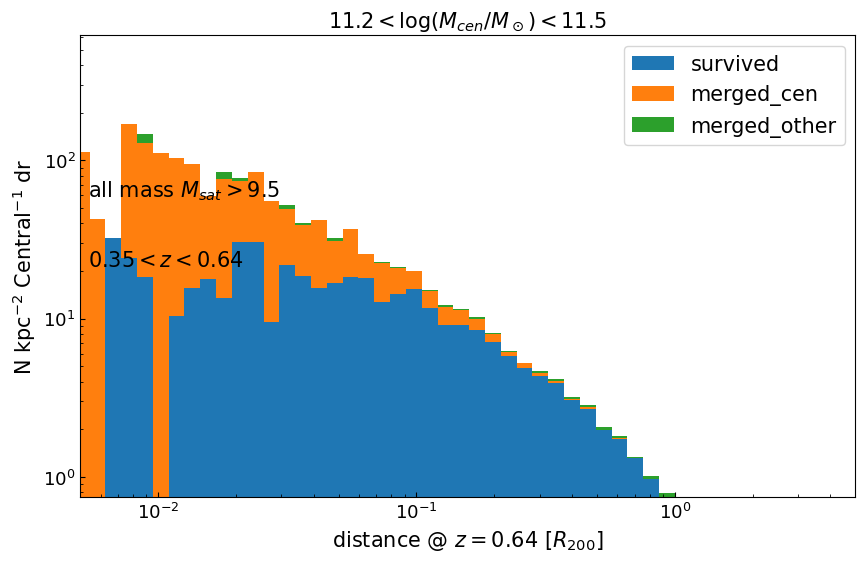

In [85]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 6))

bin_edges = 10 ** np.linspace(-3,0, num=50)
bin_left_edges = bin_edges[:-1]
bin_right_edges = bin_edges[1:]
bin_width = bin_right_edges - bin_left_edges
areas = np.pi*(bin_right_edges**2-bin_left_edges**2)

n_survived, bin_edges = np.histogram(distances_survived_list,bins=bin_edges)
n_merged_cen, bin_edges = np.histogram(distances_cen_list,bins=bin_edges)
n_merged_other, bin_edges = np.histogram(distances_merged_list,bins=bin_edges)

print(sum(n_survived),sum(n_merged_cen),sum(n_merged_other),round(sum(n_merged_cen)/sum(n_survived),4))

# n,bins,patches=plt.hist([distances_survived_list,distances_cen_list,distances_merged_list],
#          bins=bin_edges,label=,stacked=True)
plt.annotate(r'all mass $M_{sat}>9.5$',xy=(0.01,0.65),xycoords='axes fraction',fontsize=15)
plt.annotate('$'+str(tng_time[snap_end]['z'])+'<z<'+str(tng_time[snap_start]['z'])+'$',xy=(0.01,0.5),xycoords='axes fraction',fontsize=15)

plt.title('$'+str(round(np.log10(masscut_central_low)+10,1))+'<\log(M_{cen}/M_\odot)<'+str(round(np.log10(masscut_central_high)+10,1))+'$',fontsize=15)

bottom = 0
labels = ['survived','merged_cen','merged_other']
for idx,data in enumerate([n_survived,n_merged_cen,n_merged_other]):
    hist_data = data/areas/len(halo_ids_start_checked)
    axs.bar(bin_edges[:-1], hist_data , bottom=bottom, width=bin_width, align='edge',label=labels[idx])
    bottom += hist_data
    
plt.xlabel('distance @ $z='+str(tng_time[snap_start]['z'])+'~[R_{200}$]', fontsize=15)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=15)
plt.xlim([0.005,5])
plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=15)
plt.savefig('Satellites.png',dpi=150)
plt.show()

Text(0, 0.5, 'Number of Galaxies')

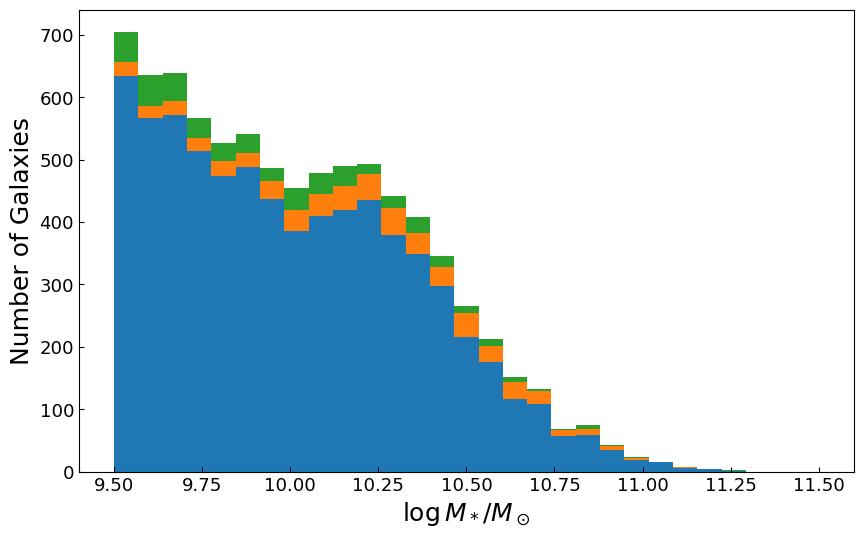

In [14]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 6))

labels = ['survived','merged_cen','merged_other']
mass_bin_edges = np.linspace(9.5,11.5, num=30)
bin_width = mass_bin_edges[1] - mass_bin_edges[0]

n_survived, mass_bin_edges = np.histogram(np.log10(mass_survived_list)+10,bins=mass_bin_edges)
n_merged_cen, mass_bin_edges = np.histogram(np.log10(mass_cen_list)+10,bins=mass_bin_edges)
n_merged_other, mass_bin_edges = np.histogram(np.log10(mass_merged_list)+10,bins=mass_bin_edges)

bottom = 0
for idx,data in enumerate([n_survived,n_merged_cen,n_merged_other]):

    axs.bar(mass_bin_edges[:-1], data , bottom=bottom, width=bin_width, align='edge',label=labels[idx])
    bottom += data

axs.set_xlabel('$\log M_*/M_\odot$',fontsize=18)
axs.set_ylabel('Number of Galaxies',fontsize=18)

In [16]:
bins=10 ** np.linspace(1.0, 3.225, num=35)
survived,bin_edges = np.histogram(distances_survived_list,bins=bins)
merged_cen, bin_edges = np.histogram(distances_cen_list,bins=bins)
merged_other, bin_edges = np.histogram(distances_merged_list,bins=bins)
disrupted, bin_edges = np.histogram(distances_dpd_list,bins=bins)
all_sats = survived + merged_other + merged_cen + disrupted

np.save(mass_show+'.npy',(merged_cen)/(all_sats))

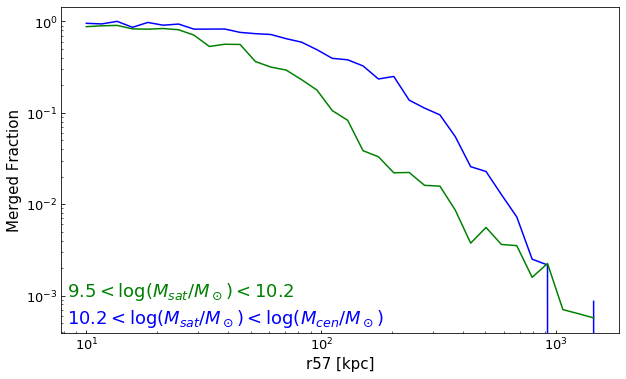

In [17]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 6))
merged_fraction_high_mass = np.load('high_mass.npy')
merged_fraction_low_mass = np.load('low_mass.npy')

plt.plot(bin_edges[:-1],merged_fraction_high_mass,color='b')
plt.plot(bin_edges[:-1],merged_fraction_low_mass,color='g')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r57 [kpc]', fontsize=15)
plt.ylabel('Merged Fraction', fontsize=15)
plt.annotate(r'$9.5<\log(M_{sat}/M_\odot)<10.2$',xy=([0.01,0.11]),xycoords='axes fraction',fontsize=18,color='g')
plt.annotate(r'$10.2<\log(M_{sat}/M_\odot)<\log(M_{cen}/M_\odot)$',xy=([0.01,0.03]),xycoords='axes fraction',fontsize=18,color='b')

plt.savefig('Satellites_merge_fraction.png')

### accretion of satellites
satellite moved from outside of 1R200 to within 1 R200

In [45]:
# load subhalos
fields = ['SubhaloPos','SubhaloMass','SubhaloStellarPhotometricsMassInRad',
          'SubhaloMassInRadType','SubhaloStellarPhotometrics','SubhaloGrNr','SubhaloVel']

snap_start=61
subhalos_start = il.groupcat.loadSubhalos(basePath,snap_start,fields=fields)
del subhalos_start['count']
subhalos_start = Table(subhalos_start)
subhalos_start.add_column(Column(data=np.arange(len(subhalos_start)),name='id'))
subhalos_start = subhalos_start[subhalos_start['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
subhalos_start.write('subhalos_migration_'+str(snap_start)+'.fits',overwrite=True)
print('finished loading subhalos_start')

snap_end=75
subhalos_end = il.groupcat.loadSubhalos(basePath, snap_end,fields=fields)
del subhalos_end['count']

subhalos_end = Table(subhalos_end)
subhalos_end.add_column(Column(data=np.arange(len(subhalos_end)),name='id'))
subhalos_end = subhalos_end[subhalos_end['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
subhalos_end.write('subhalos_migration_'+str(snap_end)+'.fits',overwrite=True)
print('finished loading subhalos_end')


finished loading subhalos_start
finished loading subhalos_end


In [93]:
save_dir = 'sat_catalogs_later/'
sat_id_wrong_length = 0
central_wrong = 0
print(snap_start,snap_end)

r_start_list = np.array([]) # distance to central
r_end_list = np.array([]) # distance to central
r_start_merged_list = np.array([])

sat_num_survived_tot = 0
sat_num_merged_tot = 0
for i in tqdm(range(len(halo_ids_start_checked))):
    a = 1/(1+tng_time[snap_start]['z']) # scale factor
    halo_id_start = halo_ids_start_checked[i]
    
    # r200 = massive_central_halos_start[i]['Group_R_Crit200']*a/0.704 #h=0.704 in kpc (physical)
    # print(massive_central_halos_start[i]['GroupNsubs'])
    try:
        # survived satellites
#         sat_ids = np.load(save_dir+str(halo_id_start)+'_sats.npy')
#         if sat_ids.shape[1] != snap_end -snap_start + 1:
#             sat_id_wrong_length+=1
#             continue
            
#         sat_ids_start = sat_ids[:,0].astype(int)
        
#         merged_sat_cen_root_ids = np.load(save_dir+str(halo_id_start)+'_merged_with_central_root_sats.npy')
#         sat_ids_start = np.append(sat_ids_start, merged_sat_cen_root_ids).astype(int)
#         sat_ids_end = sat_ids[:,snap_end-snap_start]
        
#         sat_num_survived_tot += len(sat_ids_start)
#         sat_num_merged_tot += len(merged_sat_cen_root_ids)
        
#         if len(sat_ids_start)==0 or len(sat_ids_end)==0:
#             continue

#         central_id_start = halos_start[np.in1d(halos_start['id'],halo_id_start)]['GroupFirstSub']
#         central_id_end = descendants[descendants[:,0]==central_id_start][0][snap_end-snap_start]
#         if central_id_end not in subhalos_end['id']:
#             central_wrong+=1
#             continue
        
        r_start_merged = np.load(save_dir+'distance_list_merged_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')  #kpc
        r_start = np.load(save_dir+'distance_list_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')  #kpc
        r_end = np.load(save_dir+'distance_list_3d_'+str(snap_end)+'_'+str(halo_id_start)+'.npy')  #kpc
        
        if len(r_start) == len(r_end):
            r_start_list = np.append(r_start_list, r_start) 
            r_end_list = np.append(r_end_list, r_end) 
            r_start_merged_list = np.append(r_start_merged_list,r_start_merged)
            
    except FileNotFoundError:
        print('file not found',halo_ids_start[i])

# distance in terms of r200
new_accretion = np.count_nonzero((r_start_list>1.0) & (r_end_list<1.0))
moved_out = np.count_nonzero((r_start_list<1.0) & (r_end_list>1.0))

print(sat_num_tot,new_accretion,moved_out,len(r_start_list[r_start_list<1.0])+len(r_start_merged_list[r_start_merged_list<1.0]))

61 75


 82%|████████▏ | 636/778 [00:00<00:00, 868.48it/s] 

file not found 1080


100%|██████████| 778/778 [00:00<00:00, 870.59it/s]

file not found 2609
file not found 2727
8594 2148 747 4899


In [97]:
halo_id_start=1080
r_start_merged = np.load(save_dir+'distance_list_merged_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')  #kpc
r_start = np.load(save_dir+'distance_list_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')  #kpc
r_end = np.load(save_dir+'distance_list_3d_'+str(snap_end)+'_'+str(halo_id_start)+'.npy')  #kpc

In [98]:
r_start

array([0.30738095, 0.40931693, 1.10943936, 0.31662271, 0.53777864,
       1.38792535, 1.37562002])

In [84]:
1401/4899

0.2859767299448867

### Distribution evolution plot

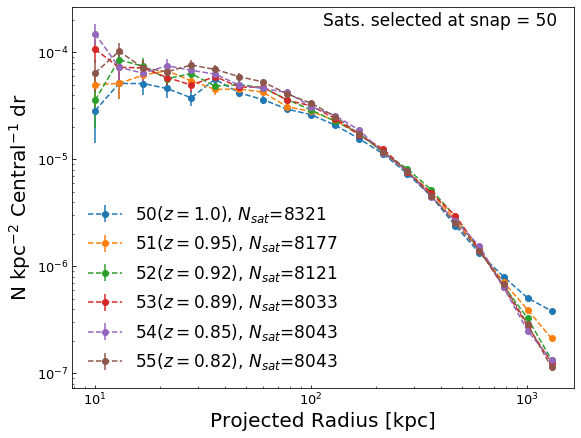

In [18]:
# make the plot
bin_edges=10 ** np.linspace(1.0, 3.225, num=21)

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(9, 7))
tng_time = Table.read('TNG_snap_time.csv')
for i in range(len(radial_z)):
    z = tng_time['z'][snaps[i]]
    plt.errorbar(bin_edges[:-1],radial_z[i]/areas/massive_counts[i],yerr=np.sqrt(radial_z[i])/areas/massive_counts[i],
             fmt='o--',label=str(snaps[i])+'($z=$'+str(z)+'), $N_{sat}$='+str(int(sum(radial_z[i]))))

plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.5,0.95),xycoords='axes fraction',fontsize=17)
plt.xscale('log')
plt.yscale('log')

plt.xlabel('Projected Radius [kpc]', fontsize=20)
plt.ylabel('N kpc$^{-2}$ Central$^{-1}$ dr', fontsize=20)
plt.legend(fontsize=17,frameon=False,loc='lower left')
plt.savefig('trace_distribution_'+str(snap_start)+'.png')

### migration of satellites

In [17]:
# load subhalos
fields = ['SubhaloPos','SubhaloMass','SubhaloStellarPhotometricsMassInRad',
          'SubhaloMassInRadType','SubhaloStellarPhotometrics','SubhaloGrNr','SubhaloVel']

snap_start=43
subhalos57 = il.groupcat.loadSubhalos(basePath,snap_start,fields=fields)
del subhalos57['count']
subhalos57 = Table(subhalos57)
subhalos57.add_column(Column(data=np.arange(len(subhalos57)),name='id'))
subhalos57 = subhalos57[subhalos57['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
subhalos57.write('subhalos_migration_'+str(snap_start)+'.fits',overwrite=True)
print('finished loading subhalos57')

snap_end=51
subhalos72 = il.groupcat.loadSubhalos(basePath, snap_end,fields=fields)
del subhalos72['count']

subhalos72 = Table(subhalos72)
subhalos72.add_column(Column(data=np.arange(len(subhalos72)),name='id'))
subhalos72 = subhalos72[subhalos72['SubhaloMassInRadType'][:,4]>0.01*0.704] #10**8 solar masses
subhalos72.write('subhalos_migration_'+str(snap_end)+'.fits',overwrite=True)
print('finished loading subhalos72')


finished loading subhalos57
finished loading subhalos72


In [19]:
r57_list = np.array([]) # distance to central
r72_list = np.array([]) # distance to central
E57_list = np.array([]) # total energy
E72_list = np.array([]) # total energy
r57_merged_list = np.array([]) # distance of merged satellites at snap_start
mass_list = np.array([])
mass_merged_list = np.array([])
logssfr_list = np.array([])

save_dir = 'sat_catalogs_later/'
print(save_dir)

fnf=0 # file_not_found count
sat_id_wrong_length = 0
central_wrong = 0
for i in range(len(halo_ids_start)):
    halo_id_start = halo_ids_start[i]
    try:
        # survived satellites
        sat_ids = np.load('sat_catalogs_later/'+str(halo_id_start)+'_sats.npy').astype(int)
        if sat_ids.shape[1] != snap_end -snap_start + 1:
            sat_id_wrong_length+=1
            continue
        sat_ids_57 = sat_ids[:,0]
        sat_ids_72 = sat_ids[:,snap_end-snap_start]
        if len(sat_ids_57)==0 or len(sat_ids_72)==0:
            continue
            
        central_id_57 = halos_start[np.in1d(halos_start['id'],halo_id_start)]['GroupFirstSub']
        central_id_72 = descendants[descendants[:,0]==central_id_57][0][snap_end-snap_start]
        if central_id_72 not in subhalos72['id']:
            central_wrong+=1
            continue
        
        r57 = np.load(save_dir+'distance_list_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')  #kpc
        r72 = np.load(save_dir+'distance_list_3d_'+str(snap_end)+'_'+str(halo_id_start)+'.npy')  #kpc
        print(r57)
        print(r72)
        m57 = subhalos57[np.in1d(subhalos57['id'],sat_ids_57)]['SubhaloMass']/0.704  # 10^10 m_sun
        m72 = subhalos72[np.in1d(subhalos72['id'],sat_ids_72)]['SubhaloMass']/0.704  # 10^10 m_sun
        M57 = subhalos57[np.in1d(subhalos57['id'],central_id_57)]['SubhaloMass']/0.704  # 10^10 m_sun
        M72 = subhalos72[np.in1d(subhalos72['id'],central_id_72)]['SubhaloMass']/0.704  # 10^10 m_sun
        v57 = np.sqrt(np.sum((subhalos57[np.in1d(subhalos57['id'],sat_ids_57)]['SubhaloVel']-subhalos57[np.in1d(subhalos57['id'],central_id_57)]['SubhaloVel'])**2,axis=1)) # km/s
        v72 = np.sqrt(np.sum((subhalos72[np.in1d(subhalos72['id'],sat_ids_72)]['SubhaloVel']-subhalos72[np.in1d(subhalos72['id'],central_id_72)]['SubhaloVel'])**2,axis=1)) # km/s
        
        r57 = r57*3.086  # kpc--m
        r72 = r72*3.086  # kpc--m
        m57 = m57*1.989  # 10^10 m_sun--kg
        m72 = m72*1.989  # 10^10 m_sun--kg
        M57 = M57*1.989e10  # 10^10 m_sun--kg
        M72 = M72*1.989e10  # 10^10 m_sun--kg
        v57 = v57*1000 # km/s--m/s
        v72 = v72*1000 # km/s--m/s
        G=6.67
        E57 = 0.5*m57*v57**2-G*M57*m57/r57
        try:
            E72 = 0.5*m72*v72**2-G*M72*m72/r72
        except ValueError:
            print(len(m72),len(v72),M72,len(r72),len(sat_ids_72))

        m57_selection = np.log(subhalos57[np.in1d(subhalos57['id'],sat_ids_57)]['SubhaloMassInRadType'][:,4]/0.704)+10  # log
        
        # merged satellites
        sat_merged_cen_ids = np.load('sat_catalogs_later/'+str(halo_id_start)+'_merged_with_central_sats.npy').astype(int)
        r57_merged = np.load('sat_catalogs_later/distance_list_merged_central_3d_'+str(snap_start)+'_'+str(halo_id_start)+'.npy')
        m57_merged = np.log(subhalos57[np.in1d(subhalos57['id'],sat_merged_cen_ids)]['SubhaloMassInRadType'][:,4]/0.704)+10   
        
        if len(r57) == len(r72) and len(r57) == len(m57):
            mass_list = np.append(mass_list,m57_selection)
            mass_merged_list = np.append(mass_merged_list, m57_merged)
            r57_list = np.append(r57_list,r57)
            r72_list = np.append(r72_list,r72)
            E57_list = np.append(E57_list,E57)
            E72_list = np.append(E72_list,E72)
            
            # merged satellites
            r57_merged_list = np.append(r57_merged_list, r57_merged)
    except FileNotFoundError:
        print('fnf error')
        fnf +=1
    
print(len(r57_merged_list),len(mass_merged_list))
print(fnf, sat_id_wrong_length,central_wrong )

sat_catalogs_later/
[1595.61384957 1636.66787083  842.74048646  741.37860366  709.3105477
  624.52080516  780.18421252  373.76660514  213.82689019  340.22454705
  128.60679479  277.88086788  554.57666747   68.95476698  242.01029523
  435.6023234   164.71949972 1413.64213378  776.36763462 1438.06074611
 1194.25650895]
[ 834.07773681  995.98456761 1270.9584375  1326.53932046 1150.98068348
 1178.69427669 1064.62430612  256.22503872  977.06387078  848.93398254
  673.35084388  857.91810516 1326.82359361  732.5780937   768.71909469
  919.73764851  961.65482548 2112.395255   1304.66543707 2351.13942583
 2066.04800069]
fnf error
[ 184.79818601  207.56947201  222.73630278  351.13307447  387.50425487
 1270.23133967 1075.60429454  437.09484754  340.91033582 1487.68289321
 1624.34174737 1487.33250261 1380.9559042   880.79182167  647.42279066
   50.54515172  439.42430216  252.21722793]
[ 136.09671597  637.14791871  195.81248572  566.41664941  397.57874444
  621.68307629  301.49991871  891.20287822 

ValueError: operands could not be broadcast together with shapes (18,3) (0,3) 

In [ ]:
# radius change of satellites
masscut = 9.5
r72_high_mass = r72_list[mass_list>masscut]
r57_high_mass = r57_list[mass_list>masscut]
r72_low_mass = r72_list[mass_list<masscut]
r57_low_mass = r57_list[mass_list<masscut]

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 10))
plt.scatter(r57_low_mass,r72_low_mass,marker='.',c='g',s=10,alpha=0.4,label='low mass (<'+str(masscut)+')')
plt.scatter(r57_high_mass,r72_high_mass,marker='.',c='b',s=10,alpha=0.4,label='high mass (>'+str(masscut)+')')
plt.plot([10,10**3.325],[10,10**3.325],'r')
plt.xlim([10,10**3.325])
plt.ylim([10,10**3.625])
plt.xscale('log')
plt.yscale('log')
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.95),xycoords='axes fraction',fontsize=17)
plt.annotate(basePath,xy=(0.05,0.89),xycoords='axes fraction',fontsize=17)

# non-parametric fit
nonpar_fit=lowess(r72_high_mass, r57_high_mass,frac=0.05)
plt.plot(nonpar_fit[:,0],nonpar_fit[:,1],'b',linewidth=2)
nonpar_fit=lowess(r72_low_mass, r57_low_mass,frac=0.05)
plt.plot(nonpar_fit[:,0],nonpar_fit[:,1],'g',linewidth=2)


plt.xlabel('r57 ', fontsize=15)
plt.ylabel('r72 ', fontsize=15)
plt.savefig('radius_change_two_snap_'+str(snap_start)+'.png')

[2185.62181212 6493.93394285 3679.0276658  ... 3223.23839092 5736.47414948
 4748.09547492] [5480.89763989 4822.78241333 4595.34525625 ... 4074.73911534 4234.07487731
 4874.12837853]


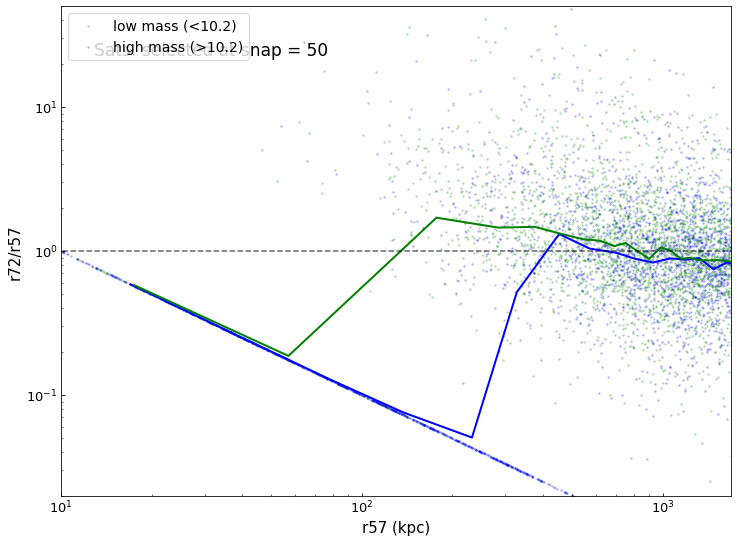

In [103]:
# plotting (mass dependence)
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(12, 9))

# cut sample (high/low mass)
masscut = 10.2
r72_high_mass = r72_list[mass_list>masscut]
r57_high_mass = r57_list[mass_list>masscut]
r72_low_mass = r72_list[mass_list<masscut]
r57_low_mass = r57_list[mass_list<masscut]
print(r72_list,r57_list)

# include merged (before snap_end) satellites
r72_high_mass = np.append(r72_high_mass,10*np.ones(len(r57_merged_list[mass_merged_list>masscut])))
r57_high_mass = np.append(r57_high_mass,r57_merged_list[mass_merged_list>masscut])
r72_low_mass = np.append(r72_low_mass,10*np.ones(len(r57_merged_list[mass_merged_list<masscut])))
r57_low_mass = np.append(r57_low_mass,r57_merged_list[mass_merged_list<masscut])

# plot
plt.scatter(r57_low_mass,r72_low_mass/r57_low_mass,marker='.',c='g',s=10,alpha=0.2,label='low mass (<'+str(masscut)+')')
plt.scatter(r57_high_mass,r72_high_mass/r57_high_mass,marker='.',c='b',s=10,alpha=0.2,label='high mass (>'+str(masscut)+')')


# running median
group_size = 160
low_mass_ratio_median_list = []
high_mass_ratio_median_list = []
low_mass_r57_median_list = []
high_mass_r57_median_list = []
ratio_low_mass = r72_low_mass/r57_low_mass
ratio_high_mass = r72_high_mass/r57_high_mass

index=0
arr1inds = r57_low_mass.argsort()
ratio_low_mass = ratio_low_mass[arr1inds[::-1]]
r57_low_mass = r57_low_mass[arr1inds[::-1]]
while index<len(r57_low_mass):
    
    low_mass_ratio_slice = ratio_low_mass[index: index + group_size - 1]
    low_mass_r57_slice = r57_low_mass[index: index + group_size - 1]
    low_mass_ratio_median = np.median(low_mass_ratio_slice)
    low_mass_r57_median = np.median(low_mass_r57_slice)
    
    low_mass_ratio_median_list.append(low_mass_ratio_median)
    low_mass_r57_median_list.append(low_mass_r57_median)
    index = index + group_size

index=0
arr1inds = r57_high_mass.argsort()
ratio_high_mass = ratio_high_mass[arr1inds[::-1]]
r57_high_mass = r57_high_mass[arr1inds[::-1]]
while index<len(r57_high_mass):
    high_mass_ratio_slice = ratio_high_mass[index: index + group_size - 1]
    high_mass_r57_slice = r57_high_mass[index: index + group_size - 1]
    high_mass_ratio_median = np.median(high_mass_ratio_slice)
    high_mass_r57_median = np.median(high_mass_r57_slice)
    
    high_mass_ratio_median_list.append(high_mass_ratio_median)
    high_mass_r57_median_list.append(high_mass_r57_median)
    index = index + group_size

plt.plot(high_mass_r57_median_list,high_mass_ratio_median_list,'b',linewidth=2)
plt.plot(low_mass_r57_median_list,low_mass_ratio_median_list,'g',linewidth=2)


# non-parametric fit
# nonpar_fit=lowess(r72_high_mass/r57_high_mass, r57_high_mass,frac=0.1)
# plt.plot(nonpar_fit[:,0],nonpar_fit[:,1],'b',linewidth=2)
# nonpar_fit=lowess(r72_low_mass/r57_low_mass, r57_low_mass,frac=0.1)
# plt.plot(nonpar_fit[:,0],nonpar_fit[:,1],'g',linewidth=2)

plt.plot([0,10000],[1,1],'--k',alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.xlim([10,10**3.225])
plt.ylim([0.02,50])
plt.legend(fontsize=14) 
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.9),xycoords='axes fraction',fontsize=17)
plt.xlabel('r57 (kpc)', fontsize=15)
plt.ylabel('r72/r57', fontsize=15)
plt.savefig('distance_ratio_change_two_snap_'+str(snap_start)+'.png',dpi=150)


### mass change of satellite galaxies

In [54]:
# half mass radius definition: ['SubhaloMassInRadType'][4]
# surface magnitude definition: ['SubhaloStellarPhotometricsMassInRad']

fields = ['SubhaloPos','SubhaloMass','SubhaloStellarPhotometricsMassInRad']
save_dir = 'sat_catalogs/' if track=='prev' else 'sat_catalogs_later/'

m72_stellar = []
m57_stellar = []
m72_subhalo = []
m57_subhalo = []
logssfr_list = []
if track == 'prev':
    halos_ids_start = np.copy(halo_ids_start)
else:
    halos_ids_start = np.copy(halo_ids_start_checked)
    
for halo_id_start in halos_ids_start:
    sat_ids = np.load(save_dir+str(halo_id_start)+'_sats.npy')
    sat_ids_start = sat_ids[:,0]
    logssfr_start = np.load(save_dir+str(halo_id_start)+'_logssfr_sats.npy')
    sat_cat = subhalos_start[np.in1d(subhalos_start['id'],sat_ids_start.astype(int))]
    
    for i,sat_id_start in enumerate(sat_ids_start):
        logssfr_list.append(logssfr_start[i])
        if track=='prev':
            tree = il.sublink.loadTree(basePath,snap_start,sat_id_start,
                               fields=['SnapNum','SubfindID','SubhaloMass','SubhaloStellarPhotometricsMassInRad','SubhaloMassInRadType'],
                               onlyMPB=True)
            
            m72_subhalo.append(tree['SubhaloMass'][0])
            m57_subhalo.append(tree['SubhaloMass'][snap_end-snap_start])
            m72_stellar.append(tree['SubhaloMassInRadType'][4][0])
            m57_stellar.append(tree['SubhaloMassInRadType'][4][snap_end-snap_start])
                
        else:
            snap_end =snaps[-1] #72 
            tree = il.sublink.loadTree(basePath,snap_start,sat_id_start,
                               fields=['SnapNum','SubfindID','SubhaloMass','SubhaloStellarPhotometricsMassInRad','SubhaloMassInRadType'],
                               onlyMDB=True)
            m72_subhalo.append(tree['SubhaloMass'][-(snap_end-snap_start)])
            m57_subhalo.append(subhalos_start[subhalos_start['id']==int(sat_id_start)]['SubhaloMass'])
        
            
            m72_stellar.append(tree['SubhaloMassInRadType'][:,4][-(snap_end-snap_start)])
            m57_stellar.append(subhalos_start[subhalos_start['id']==int(sat_id_start)]['SubhaloMassInRadType'][0][4])


m72_stellar = np.array(m72_stellar)
m57_stellar = np.array(m57_stellar)
m72_subhalo = np.array(m72_subhalo)
m57_subhalo = np.array(m57_subhalo)     


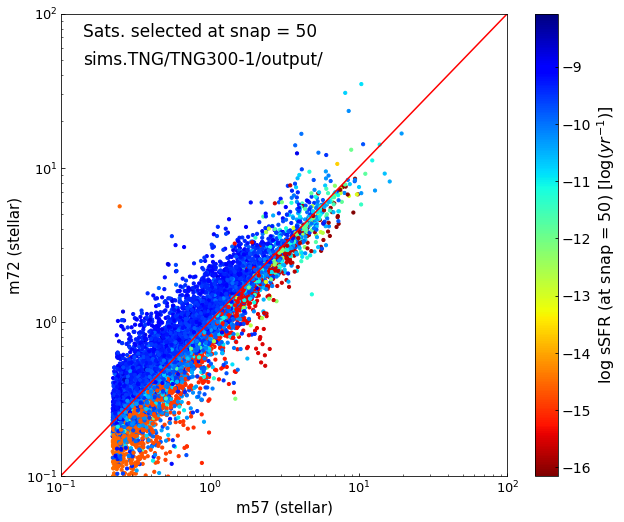

In [55]:
# stellar mass change of satellites

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 8.5))
plt.scatter(m57_stellar,m72_stellar,c=np.array(logssfr_list),s=10,cmap='jet_r')

plt.plot([0.1,1e2],[0.1,1e2],'r')
plt.xlim([0.1,1e2])
plt.ylim([0.1,1e2])
plt.xscale('log')
plt.yscale('log')
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.95),xycoords='axes fraction',fontsize=17)
plt.annotate(basePath,xy=(0.05,0.89),xycoords='axes fraction',fontsize=17)

cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=14) 
cbar.set_label(r'log sSFR (at snap = '+str(snap_start)+') [$\log(yr^{-1})$]',size=16)

plt.xlabel('m57 (stellar)', fontsize=15)
plt.ylabel('m72 (stellar)', fontsize=15)
plt.savefig('mass_change_two_snap_'+str(snap_start)+'.png')

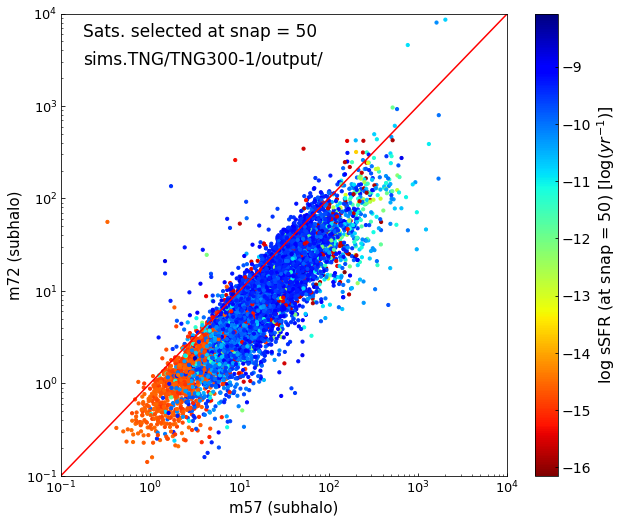

In [56]:
# subhalo mass change of satellites

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 8.5))

plt.scatter(m57_subhalo,m72_subhalo,c=np.array(logssfr_list),s=10,cmap='jet_r')

plt.plot([0.1,1e4],[0.1,1e4],'r')
plt.xlim([0.1,1e4])
plt.ylim([0.1,1e4])
plt.xscale('log')
plt.yscale('log')
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.95),xycoords='axes fraction',fontsize=17)
plt.annotate(basePath,xy=(0.05,0.89),xycoords='axes fraction',fontsize=17)

cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=14) 
cbar.set_label(r'log sSFR (at snap = '+str(snap_start)+') [$\log(yr^{-1})$]',size=16)

plt.xlabel('m57 (subhalo)', fontsize=15)
plt.ylabel('m72 (subhalo)', fontsize=15)
plt.savefig('mass_subhalo_change_two_snap_'+str(snap_start)+'.png')

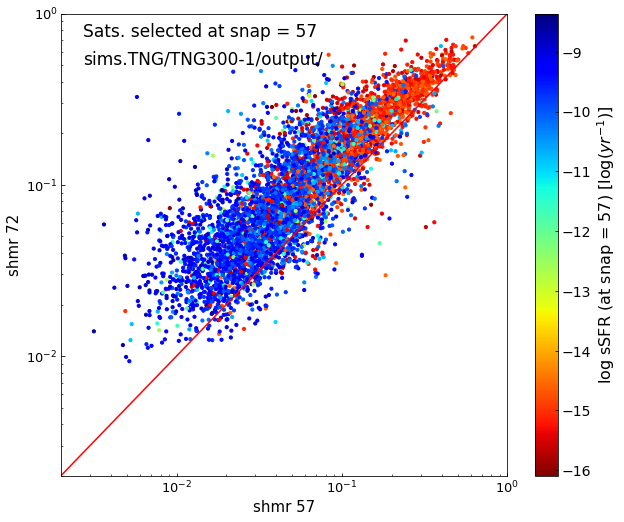

In [66]:
# shmr change of satellites

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 8.5))

plt.scatter(np.array(m57_stellar)/np.array(m57_subhalo),np.array(m72_stellar)/np.array(m72_subhalo)
            ,c=np.array(logssfr_list),s=10,cmap='jet_r')

plt.plot([0.002,1],[0.002,1],'r')
plt.xlim([0.002,1])
plt.ylim([0.002,1])
plt.xscale('log')
plt.yscale('log')
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.95),xycoords='axes fraction',fontsize=17)
plt.annotate(basePath,xy=(0.05,0.89),xycoords='axes fraction',fontsize=17)

cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=14) 
cbar.set_label(r'log sSFR (at snap = '+str(snap_start)+') [$\log(yr^{-1})$]',size=16)

plt.xlabel('shmr 57', fontsize=15)
plt.ylabel('shmr 72', fontsize=15)
plt.savefig('shmr_change_two_snap_'+str(snap_start)+'.png')


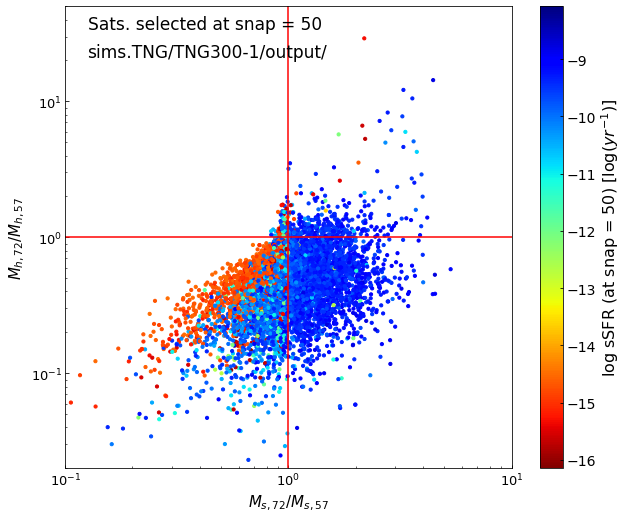

In [82]:
# shmr change of satellites

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(10, 8.5))
sterllar_ratio = np.array(m72_stellar)/np.array(m57_stellar)
subhalo_ratio = np.array(m72_subhalo)/np.array(m57_subhalo.ravel())
plt.scatter(sterllar_ratio,subhalo_ratio,c=np.array(logssfr_list),s=10,cmap='jet_r')

plt.plot([0,100],[1,1],'r')
plt.plot([1,1],[0,100],'r')
plt.xlim([0.1,10])
plt.ylim([0.02,50])
plt.xscale('log')
plt.yscale('log')
plt.annotate('Sats. selected at snap = '+str(snap_start),xy=(0.05,0.95),xycoords='axes fraction',fontsize=17)
plt.annotate(basePath,xy=(0.05,0.89),xycoords='axes fraction',fontsize=17)

cbar = plt.colorbar()
cbar.ax.tick_params(labelsize=14) 
cbar.set_label(r'log sSFR (at snap = '+str(snap_start)+') [$\log(yr^{-1})$]',size=16)

plt.xlabel(r'$M_{s,72}/M_{s,57}$', fontsize=15)
plt.ylabel(r'$M_{h,72}/M_{h,57}$', fontsize=15)
plt.savefig('shmr_change_two_snap_'+str(snap_start)+'.png')

In [11]:
save_dir = 'sat_catalogs/' if track=='prev' else 'sat_catalogs_later/'
if track == 'prev':
    halo_ids_start = np.copy(halo_ids_start)
    tree_length = snap_start+1
    onlymdb = False
    onlympb = True
else:
    halo_ids_start = np.copy(halo_ids_start_checked)
    tree_length = 99 - snap_start 
    onlymdb = True
    onlympb = False

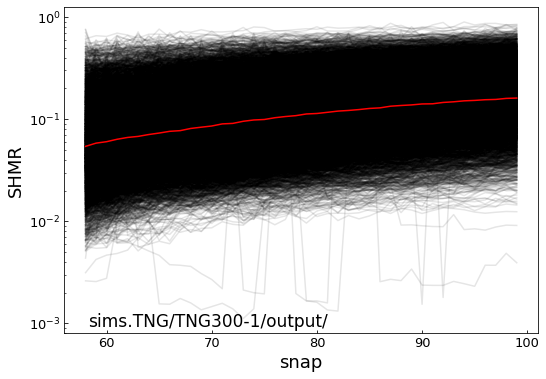

In [74]:
# shmr change as a function of redshift

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8.5, 6))

m_subhalo = np.array(np.ones(tree_length))
m_stellar = np.array(np.ones(tree_length))
for halo_id_start in halo_ids_start:
    sat_ids = np.load(save_dir+str(halo_id_start)+'_sats.npy')
    sat_ids_start = sat_ids[:,0]
    sat_cat = subhalos[sat_ids_start.astype(int)]
    
    for sat_id in sat_ids_start:
        tree = il.sublink.loadTree(basePath,snap_start,sat_id,
                               fields=['SnapNum','SubfindID','SubhaloMass','SubhaloStellarPhotometricsMassInRad'],
                               onlyMDB=onlymdb,onlyMPB=onlympb)
        if tree == None:  
            continue
        
        if len(tree['SubhaloMass'])==tree_length:
            snaps = tree['SnapNum'][:tree_length]
            m_subhalo = np.vstack([m_subhalo,  np.array(tree['SubhaloMass'][:tree_length])])
            m_stellar = np.vstack([m_stellar, np.array(tree['SubhaloStellarPhotometricsMassInRad'][:tree_length])])
        
            plt.plot(tree['SnapNum'][:tree_length],
                     tree['SubhaloStellarPhotometricsMassInRad'][:tree_length]/tree['SubhaloMass'][:tree_length],
                     'k',alpha=0.1)
    
m_subhalo = np.array(m_subhalo)
m_stellar = np.array(m_stellar)
plt.plot(snaps,np.median(m_stellar,axis=0)/np.median(m_subhalo,axis=0),'r')
plt.annotate(basePath,xy=(0.05,0.02),xycoords='axes fraction',fontsize=17)

plt.xlabel('snap',fontsize=18)
plt.ylabel('SHMR',fontsize=18)
plt.yscale('log')
plt.savefig('shmr_change_snaps_'+str(snap_start)+'.png')


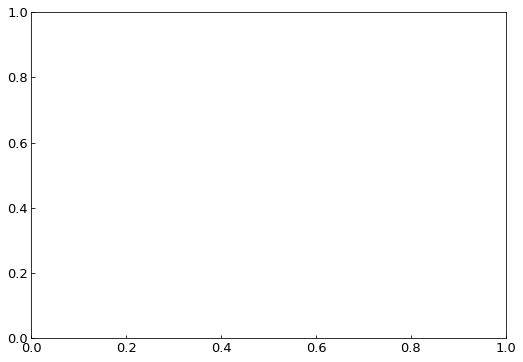

In [37]:
# radius change as a function of redshift

fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8.5, 6))

r_subhalo = np.array(np.ones(tree_length))
for halo_id_start in halo_ids_start[:10]:
    sat_ids = np.load(save_dir+str(halo_id_start)+'_sats.npy')
    sat_ids_start = sat_ids[:,0]
    sat_cat = subhalos[sat_ids_start.astype(int)]
    halo = halos_start[halo_id]
    
    for sat_id in sat_ids_start:
        tree = il.sublink.loadTree(basePath,snap_start,sat_id,
                               fields=['SnapNum','SubfindID','SubhaloPos'],
                               onlyMDB=onlymdb,onlyMPB=onlympb)
        if tree == None:  
            continue
        
        if len(tree['SubhaloMass'])==tree_length:
            snaps = tree['SnapNum'][:tree_length]
            r_subhalo = np.vstack([m_subhalo,  np.array(tree['SubhaloMass'][:tree_length])])
        
            plt.plot(tree['SnapNum'][:tree_length],
                     tree['SubhaloStellarPhotometricsMassInRad'][:tree_length]/tree['SubhaloMass'][:tree_length],
                     'k',alpha=0.1)
    
m_subhalo = np.array(m_subhalo)
plt.annotate(basePath,xy=(0.05,0.02),xycoords='axes fraction',fontsize=17)

plt.xlabel('snap',fontsize=18)
plt.ylabel('SHMR',fontsize=18)
plt.yscale('log')
plt.savefig('r_change_snaps_'+str(snap_start)+'.png')

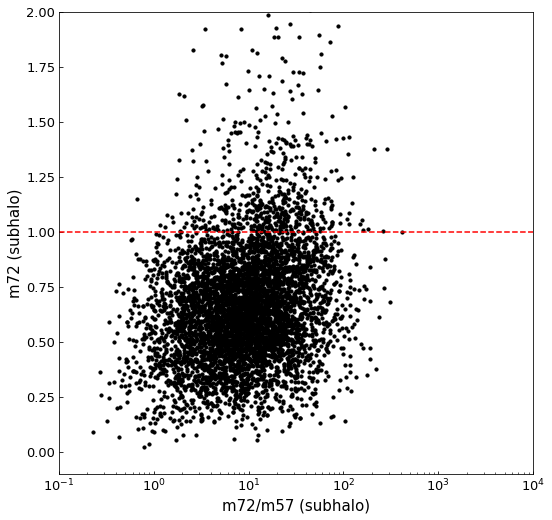

In [67]:
# subhalo mass change of satellites
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8.5, 8.5))
plt.scatter(m72_subhalo,np.array(m72_subhalo)/np.array(m57_subhalo),c='k',s=10)

plt.plot([0.1,1e4],[1,1],'--r')
plt.xlim([0.1,1e4])
plt.ylim([-0.1,2])
plt.xscale('log')
# plt.yscale('log')

plt.xlabel('m72/m57 (subhalo)', fontsize=15)
plt.ylabel('m72 (subhalo)', fontsize=15)
plt.savefig('mass_subhalo_ratio_change_two_snap.png')

### Halo Mass of centrals

11.0001


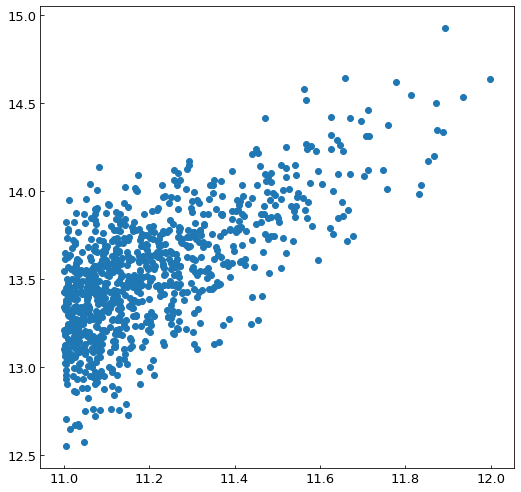

In [18]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8.5, 8.5))
mh = np.log10(halos_start[halo_ids_start]['Group_M_Crit200']/0.704)+10
ms = np.log10(subhalos_start[central_ids_start]['SubhaloStellarPhotometricsMassInRad']/0.704)+10
print(min(ms))
np.save('ms_mh_central.npy',np.asarray([ms,mh]))
plt.scatter(ms,mh)

### mass growth of central galaxies

In [14]:
print(track)
snaps = np.arange(snap_start,snap_start-19,-5) if track =='prev' else np.arange(snap_start,snap_start+19,5)
if track == 'prev':
    onlymdb = False
    onlympb = True
else:
    onlymdb = True
    onlympb = False

later


57 later
Number of centrals tracked: 886


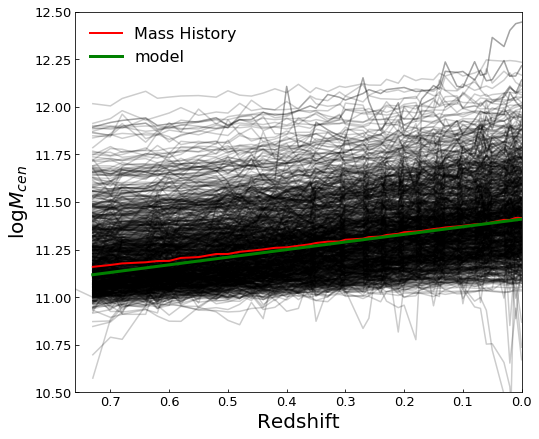

In [17]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 7))
tree_length=99-snap_start
print(snap_start,track)

tng_time = Table.read('TNG_snap_time.csv')
mass_list = np.array(np.ones(tree_length))
mass_sf_list = np.array(np.ones(tree_length))
mass_ratio_list = np.array(np.ones(tree_length))
for central_id_start in central_ids_start:
    tree = il.sublink.loadTree(basePath,snap_start,central_id_start,
                             fields=['SnapNum','SubfindID','SubhaloMass','SubhaloStellarPhotometricsMassInRad','SubhaloSFR'],
                             onlyMPB=onlympb, onlyMDB=onlymdb)
    
    # snapNum vs. Stellar Mass  (mass growth recorded by simulation)
    snaps_tree = tree['SnapNum'][:tree_length]
    zs = tng_time['z'][snaps_tree]
    if len(snaps_tree)<tree_length: continue
        
    mass_growth_record = np.array(tree['SubhaloStellarPhotometricsMassInRad'][:tree_length])/0.704
    mass_list = np.vstack([mass_list,mass_growth_record])
    plt.plot(zs, np.log10(mass_growth_record)+10,'k',alpha=0.2)
    
# #     predict mass growth from SFR
#     mass_sf = [mass_growth_record[tree_length-1]]
#     mass_ratio = mass_growth_record/mass_sf 
#     for snap in snaps[:-1]:
#         mass_sf.append(mass_sf[-1]+0.1*tree['SubhaloSFR'][np.where(snaps==snap)[0][0]]*
#                        (tng_time['age'][snap]-tng_time['age'][snap-1]))
#     try:
#         mass_sf_list = np.vstack([mass_sf_list,np.array(mass_sf)])
#         mass_ratio_list = np.vstack([mass_ratio_list,mass_ratio])
#     except ValueError:
#         continue

mass_list = np.log10(mass_list[1:])+10
mass_sf_list = np.log10(mass_sf_list[1:])+10
mass_ratio_list = np.log10(mass_ratio_list[1:])+10
print('Number of centrals tracked:',len(mass_list))

# plot median trend
plt.plot(zs,np.median(mass_list,axis=0),color='r',linewidth=2,label='Mass History')
# plt.plot(np.flip(zs,axis=0),np.median(mass_sf_list,axis=0),color='b',linewidth=2,label='estimate from SF')

# model
zs_model = np.linspace(0,0.73,100)
ms_cen_model = 11.41-0.4*zs_model
plt.plot(zs_model,ms_cen_model,'g',label='model',linewidth=3)

plt.xlabel('Redshift', fontsize=20)
plt.ylabel(r'$\log M_{cen}$', fontsize=20)
plt.ylim([10.5,12.5])
plt.xlim([0,tng_time['z'][snap_start]])
plt.gca().invert_xaxis()
plt.legend(fontsize=16,frameon=False)
plt.savefig('stellar_mass_growth_central.png')

In [ ]:
fig, axs = plt.subplots(1, 1, sharex=True,sharey='row', figsize=(8, 7))
tree_length=99-snap_start

tng_time = Table.read('TNG_snap_time.csv')
mass_list = np.array(np.ones(tree_length))
print(snap_start,track)

for central_id_start in central_ids_start:
    tree = il.sublink.loadTree(basePath,snap_start,central_id_start,
                             fields=['SnapNum','SubfindID','SubhaloMass','SubhaloGrNr'],
                             onlyMPB=onlympb, onlyMDB=onlymdb)
    
    # snapNum vs. Stellar Mass  (mass growth recorded by simulation)
    snaps_tree = tree['SnapNum'][:tree_length]
    zs = tng_time['z'][snaps_tree]
    if len(snaps_tree)<tree_length: continue
    
    halo_mass_growth_record = []
    halo_ids_record = tree['SubhaloGrNr'][:tree_length]
    for i,snap in enumerate(snaps_tree):
        halo_record = il.groupcat.loadSingle(basePath, snap, haloID=halo_ids_record[i])
        halo_mass_growth_record.append(halo_record['GroupMass'])
        
#     mass_growth_record = np.array(tree['SubhaloMass'][:tree_length])/0.704
    mass_growth_record = np.array(halo_mass_growth_record)/0.704
    mass_list = np.vstack([mass_list,mass_growth_record])

    plt.plot(zs, np.log10(mass_growth_record)+10,'k',alpha=0.2)

mass_list = np.log10(mass_list[1:])+10
print('Number of centrals tracked:',len(mass_list))

# plot median trend
plt.plot(zs,np.median(mass_list,axis=0),color='r',linewidth=2,label='Mass History')
plt.xlabel('Redshift', fontsize=20)
plt.ylabel(r'$\log M_{cen}$', fontsize=20)
plt.ylim([12.5,16])
plt.xlim([0,tng_time['z'][snap_start]])
plt.gca().invert_xaxis()
plt.legend(fontsize=18,frameon=False)
plt.savefig('subhalo_mass_growth_central.png')

In [ ]:
plt.plot(tree['SnapNum'][:50],np.median(mass_ratio_list,axis=0),color='r',linewidth=2,label='$M_{SFR}/M_{stellar}$')

plt.xlabel('snap', fontsize=20)
plt.ylabel('M_central', fontsize=20)
plt.yscale('log')
plt.xlim([22.5,72])
plt.legend(fontsize=18,frameon=False)
plt.savefig('mass_growth_central.png')